# Pretraitement des donnees - DPE Hauts-de-France

Ce notebook applique, etape par etape, les decisions justifiees dans `EDA_dpe.ipynb`. Chaque
transformation est ecrite au moment ou elle est necessaire, accompagnee d'une verification
visuelle ou statistique de son effet.

**Plan :**
1. Import des librairies et chargement
2. Regroupement de la variable cible
3. Suppression des variables non pertinentes et quasi-constantes
4. Traitement des valeurs aberrantes
5. Traitement des valeurs manquantes
6. Analyse des redondances entre variables qualitatives
7. Agregation des variables catégorielles a forte cardinalite moderee
8. Regroupement des modalites rares (haute cardinalite)
9. Encodage ordinal et export final

## 1. Import des librairies et chargement

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import itertools
from collections import defaultdict
from scipy.cluster.hierarchy import linkage, dendrogram

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100})

TARGET = "etiquette_dpe"

In [20]:
df_data = pd.read_csv('../data/dpe_hauts_de_france_2025-07-01_to_2025-12-31_half.csv', sep=',')
print(f"Dataset brut : {df_data.shape[0]:,} lignes x {df_data.shape[1]} colonnes")
df_data.head()

Dataset brut : 57,826 lignes x 46 colonnes


,etiquette_dpe,numero_dpe,date_etablissement_dpe,code_region_ban,code_departement_ban,code_postal_ban,code_insee_ban,nom_commune_ban,zone_climatique,classe_altitude,...,configuration_installation_ecs_n1,type_generateur_n1_ecs_n1,type_generateur_chauffage_principal_ecs,type_energie_principale_ecs,type_energie_generateur_n1_ecs_n1,usage_generateur_n1_ecs_n1,volume_stockage_generateur_n1_ecs_n1,ventilation_posterieure_2012,type_installation_solaire_n1,production_electricite_pv_kwhep_par_an
0,C,2559E3504406H,2025-11-05,32,59,59320,59286,Haubourdin,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,Chaudière gaz à condensation après 2015,Chaudière gaz à condensation après 2015,Gaz naturel,Gaz naturel,chauffage + ecs,0.0,1,Non affecté,0.0
1,F,2559E2432688J,2025-07-24,32,59,59360,59136,Le Cateau-Cambrésis,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,Chaudière gaz à condensation 2001-2015,NaN,Gaz naturel,Gaz naturel,chauffage + ecs,0.0,0,Non affecté,0.0
2,C,2502E3087497D,2025-09-30,32,2,2170,2558,Le Nouvion-en-Thiérache,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,CET sur air ambiant (sur local non chauffé) ap...,NaN,Électricité,Électricité,ecs,150.0,1,Non affecté,0.0
3,E,2502E3013330O,2025-09-23,32,2,2000,2408,Laon,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,Ballon électrique à accumulation vertical Caté...,NaN,Électricité,Électricité,ecs,150.0,0,Non affecté,0.0
4,C,2562E2831514Y,2025-09-08,32,62,62180,62688,Rang-du-Fliers,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,Chaudière gaz à condensation après 2015,Chaudière gaz à condensation après 2015,Gaz naturel,Gaz naturel,chauffage + ecs,0.0,0,Non affecté,0.0


## 2. Regroupement de la variable cible

L'EDA (section 2) a montre un desequilibre extreme de la cible a 7 niveaux (ratio 38:1 entre
A et C). Le regroupement suivant s'appuie sur les seuils reglementaires du DPE : A/B pour les
logements tres performants, C/D pour les logements dans la moyenne, E/F/G pour les logements
energivores a renover en priorite.

In [21]:
mapping_target = {
    "A": "Performant", "B": "Performant",
    "C": "Passable", "D": "Passable",
    "E": "Energivore", "F": "Energivore", "G": "Energivore",
}

df_data['etiquette_dpe'] = df_data['etiquette_dpe'].map(mapping_target)
df_data.head()

,etiquette_dpe,numero_dpe,date_etablissement_dpe,code_region_ban,code_departement_ban,code_postal_ban,code_insee_ban,nom_commune_ban,zone_climatique,classe_altitude,...,configuration_installation_ecs_n1,type_generateur_n1_ecs_n1,type_generateur_chauffage_principal_ecs,type_energie_principale_ecs,type_energie_generateur_n1_ecs_n1,usage_generateur_n1_ecs_n1,volume_stockage_generateur_n1_ecs_n1,ventilation_posterieure_2012,type_installation_solaire_n1,production_electricite_pv_kwhep_par_an
0,Passable,2559E3504406H,2025-11-05,32,59,59320,59286,Haubourdin,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,Chaudière gaz à condensation après 2015,Chaudière gaz à condensation après 2015,Gaz naturel,Gaz naturel,chauffage + ecs,0.0,1,Non affecté,0.0
1,Energivore,2559E2432688J,2025-07-24,32,59,59360,59136,Le Cateau-Cambrésis,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,Chaudière gaz à condensation 2001-2015,NaN,Gaz naturel,Gaz naturel,chauffage + ecs,0.0,0,Non affecté,0.0
2,Passable,2502E3087497D,2025-09-30,32,2,2170,2558,Le Nouvion-en-Thiérache,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,CET sur air ambiant (sur local non chauffé) ap...,NaN,Électricité,Électricité,ecs,150.0,1,Non affecté,0.0
3,Energivore,2502E3013330O,2025-09-23,32,2,2000,2408,Laon,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,Ballon électrique à accumulation vertical Caté...,NaN,Électricité,Électricité,ecs,150.0,0,Non affecté,0.0
4,Passable,2562E2831514Y,2025-09-08,32,62,62180,62688,Rang-du-Fliers,H1a,inférieur à 400m,...,Un seul système d'ECS sans solaire,Chaudière gaz à condensation après 2015,Chaudière gaz à condensation après 2015,Gaz naturel,Gaz naturel,chauffage + ecs,0.0,0,Non affecté,0.0


In [22]:
print(f"Dataset : {df_data.shape[0]:,} lignes x {df_data.shape[1]} colonnes")
print(f"Valeurs manquantes : {df_data.isnull().sum().sum()}")
print()
print("Distribution de la cible :")
vc = df_data["etiquette_dpe"].value_counts()
for label, count in vc.items():
    pct = count / len(df_data) * 100
    print(f"  {label:<12} {count:7,}  ({pct:5.1f}%)  {'#' * int(pct / 1.5)}")

Dataset : 57,826 lignes x 46 colonnes
Valeurs manquantes : 317609

Distribution de la cible :
  Passable      41,423  ( 71.6%)  ###############################################
  Energivore    13,974  ( 24.2%)  ################
  Performant     2,429  (  4.2%)  ##


#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Le regroupement en 3 classes reduit le desequilibre a un niveau gerable tout en restant
interpretable pour un usage metier : chaque classe correspond a une decision operationnelle
differente (acheter en confiance, negocier, ou anticiper des travaux de renovation).

## 3. Suppression des variables non pertinentes et quasi-constantes

### 3.1 Variables sans interet pour la modelisation

Identifiants, dates et localisation fine n'apportent aucun pouvoir de generalisation a un
modele : ce sont des cles uniques ou quasi-uniques, pas des caracteristiques du logement.

In [23]:
unecessary_columns = [
    'numero_dpe', 'date_etablissement_dpe', 'code_region_ban', 'code_departement_ban',
    'code_postal_ban', 'code_insee_ban', 'nom_commune_ban', 'numero_etage_appartement',
]
unecessary_columns = [c for c in unecessary_columns if c in df_data.columns]

df_data = df_data.drop(columns=unecessary_columns)
print(f"Colonnes supprimees ({len(unecessary_columns)}) : {unecessary_columns}")
print(f"Dataset : {df_data.shape[0]:,} lignes x {df_data.shape[1]} colonnes")

Colonnes supprimees (8) : ['numero_dpe', 'date_etablissement_dpe', 'code_region_ban', 'code_departement_ban', 'code_postal_ban', 'code_insee_ban', 'nom_commune_ban', 'numero_etage_appartement']
Dataset : 57,826 lignes x 38 colonnes


### 3.2 Variables quasi-constantes

Une colonne dont une seule valeur represente plus de 95% des observations n'apporte presque
pas de variabilite au modele : elle se comporte essentiellement comme du bruit plutot que
comme un signal utile.

In [24]:
quasi_cst = [
    c for c in df_data.columns
    if c != TARGET
    and df_data[c].value_counts(normalize=True).iloc[0] > 0.95
]

if quasi_cst:
    print(f"Colonnes quasi-constantes detectees ({len(quasi_cst)}) :")
    for c in quasi_cst:
        top_val = df_data[c].value_counts(normalize=True).iloc[0]
        top_lab = df_data[c].value_counts().index[0]
        print(f"  {c:<50}  '{top_lab}' ({top_val:.1%})")
    df_data = df_data.drop(columns=quasi_cst)
else:
    print("Aucune colonne quasi-constante detectee")

print(f"\nDataset : {df_data.shape[0]:,} lignes x {df_data.shape[1]} colonnes")

Colonnes quasi-constantes detectees (5) :
  zone_climatique                                     'H1a' (99.9%)
  classe_altitude                                     'inférieur à 400m' (100.0%)
  configuration_installation_ecs_n1                   'Un seul système d'ECS sans solaire' (98.6%)
  type_installation_solaire_n1                        'Non affecté' (99.3%)
  production_electricite_pv_kwhep_par_an              '0.0' (99.0%)

Dataset : 57,826 lignes x 33 colonnes


#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Ces variables, deja reperees dans l'EDA (section 5) avec plus de 95% d'une seule modalite,
n'apportent quasiment aucune information discriminante. Leur suppression reduit la
dimensionnalite sans perte de pouvoir predictif.

## 4. Traitement des valeurs aberrantes

L'EDA (section 4.1) a identifie visuellement des valeurs extremes sur `hauteur_sous_plafond`
(jusqu'a 240m, impossible pour un logement) ainsi qu'une forte proportion de zeros avec une
queue de distribution longue sur les variables de stockage ECS et de production photovoltaique.

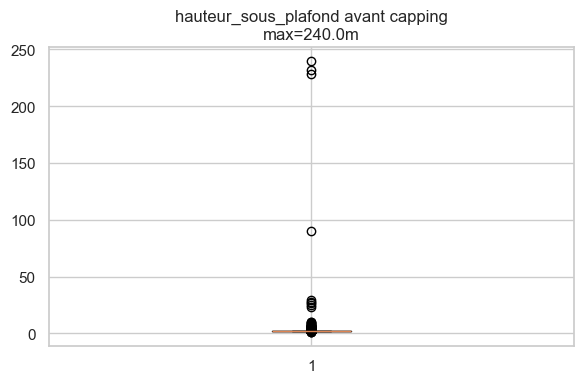

In [25]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(df_data["hauteur_sous_plafond"].dropna(), vert=True)
ax.set_title(f"hauteur_sous_plafond avant capping\nmax={df_data['hauteur_sous_plafond'].max():.1f}m")
plt.tight_layout()
plt.show()

### 4.1 Capping de `hauteur_sous_plafond`

In [26]:
n_corrected = (df_data["hauteur_sous_plafond"] > 6.0).sum()
df_data["hauteur_sous_plafond"] = df_data["hauteur_sous_plafond"].clip(upper=6.0)
print(f"hauteur_sous_plafond ecretee a 6m, valeur jugee physiquement raisonnable pour un logement")
print(f"{n_corrected} valeurs corrigees")

hauteur_sous_plafond ecretee a 6m, valeur jugee physiquement raisonnable pour un logement
22 valeurs corrigees


### 4.2 Transformation des variables a forte proportion de zeros

In [27]:
for col in ["volume_stockage_generateur_n1_ecs_n1"]:
    if col in df_data.columns:
        df_data[col] = np.log1p(df_data[col])
        print(f"{col} -> log1p (reduit l'asymetrie sans perdre l'information des zeros)")

volume_stockage_generateur_n1_ecs_n1 -> log1p (reduit l'asymetrie sans perdre l'information des zeros)


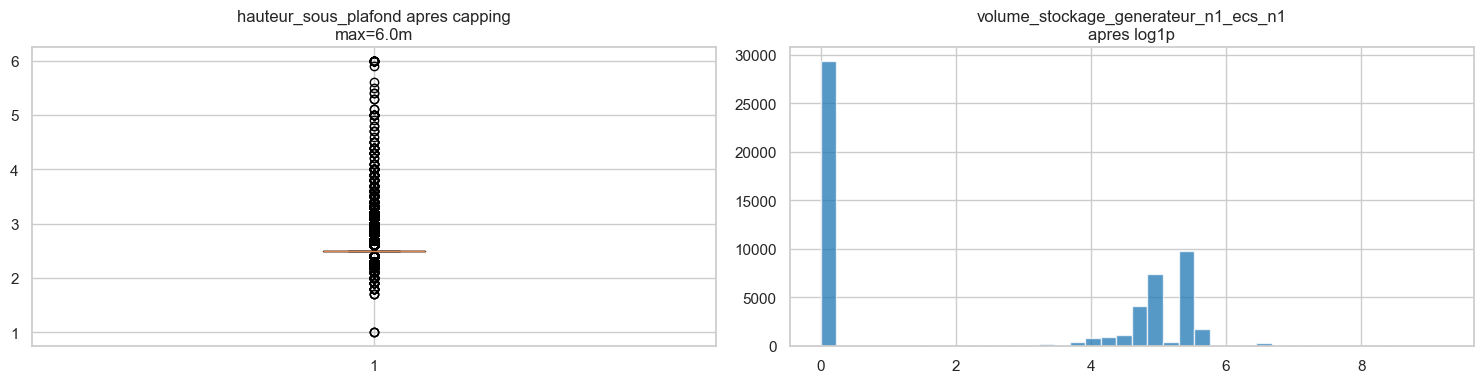

Dataset : 57,826 lignes x 33 colonnes


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

ax = axes[0]
ax.boxplot(df_data["hauteur_sous_plafond"].dropna(), vert=True)
ax.set_title(f"hauteur_sous_plafond apres capping\nmax={df_data['hauteur_sous_plafond'].max():.1f}m")

for ax, col in zip(axes[1:], ["volume_stockage_generateur_n1_ecs_n1"]):
    ax.hist(df_data[col].dropna(), bins=40, color="#1f77b4", alpha=0.75)
    ax.set_title(f"{col}\napres log1p")

plt.tight_layout()
plt.show()

print(f"Dataset : {df_data.shape[0]:,} lignes x {df_data.shape[1]} colonnes")

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Le capping ramene la valeur maximale de `hauteur_sous_plafond` a une borne physiquement
plausible, conformement a l'observation faite dans l'EDA. La transformation `log1p` compresse
la queue de distribution des variables a forte proportion de zeros sans supprimer
l'information des logements non equipes.

## 5. Traitement des valeurs manquantes

C:\Users\berul\AppData\Local\Temp\ipykernel_21244\1534211901.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=missing[missing['percent'] > 0], x='percent', y='variables', palette='viridis')


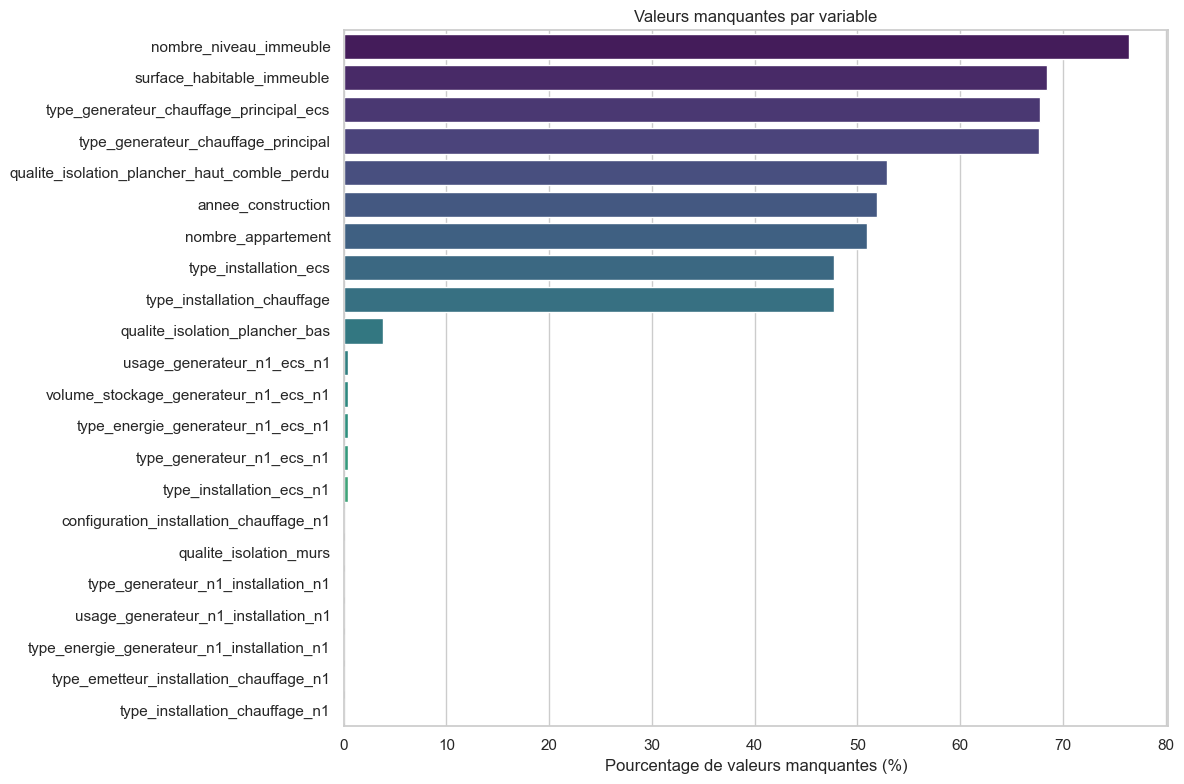

In [29]:
missing = (
    df_data.isnull().sum()
    .reset_index()
    .rename(columns={'index': 'variables', 0: 'counts'})
)
missing['percent'] = (missing['counts'] / len(df_data)) * 100
missing = missing.sort_values('percent', ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(data=missing[missing['percent'] > 0], x='percent', y='variables', palette='viridis')
plt.xlabel("Pourcentage de valeurs manquantes (%)")
plt.ylabel("")
plt.title("Valeurs manquantes par variable")
plt.tight_layout()
plt.show()

### 5.1 Suppression des colonnes structurellement incompletes

In [30]:
missing_over_45 = missing[missing['percent'] > 45]
missing_over_45

,variables,counts,percent
6,nombre_niveau_immeuble,44188,76.415453
5,surface_habitable_immeuble,39589,68.462283
27,type_generateur_chauffage_principal_ecs,39175,67.746342
18,type_generateur_chauffage_principal,39130,67.668523
14,qualite_isolation_plancher_haut_comble_perdu,30566,52.858576
4,annee_construction,30028,51.928198
7,nombre_appartement,29440,50.911355
24,type_installation_ecs,27613,47.751876
15,type_installation_chauffage,27613,47.751876


In [35]:
missing_cols_45 = missing_over_45['variables'].tolist()

df_data_clean1 = df_data.drop(columns=missing_cols_45)
print(f"Colonnes supprimees ({len(missing_cols_45)}) : {missing_cols_45}")
print(f"Dataset : {df_data_clean1.shape[0]:,} lignes x {df_data_clean1.shape[1]} colonnes")

### Suppression de toutes autres colonnes vides

df_data_clean1.dropna(inplace = True)


Colonnes supprimees (9) : ['nombre_niveau_immeuble', 'surface_habitable_immeuble', 'type_generateur_chauffage_principal_ecs', 'type_generateur_chauffage_principal', 'qualite_isolation_plancher_haut_comble_perdu', 'annee_construction', 'nombre_appartement', 'type_installation_ecs', 'type_installation_chauffage']
Dataset : 57,826 lignes x 24 colonnes


### 5.2 Verification des manquants residuels

In [36]:
missing_restant = (
    df_data_clean1.isnull().sum()
    .reset_index()
    .rename(columns={'index': 'variables', 0: 'counts'})
)
missing_restant['percent'] = (missing_restant['counts'] / len(df_data_clean1)) * 100
missing_restant[missing_restant['percent'] > 0]

,variables,counts,percent


### 5.3 Suppression des lignes residuelles incompletes

In [37]:
dist_avant = df_data_clean1["etiquette_dpe"].value_counts(normalize=True)
df_data_clean = df_data_clean1.dropna().copy()
dist_apres = df_data_clean["etiquette_dpe"].value_counts(normalize=True)

print(f"{'Classe':<14} {'Avant':>10} {'Apres':>10} {'Delta':>10}")
print("-" * 46)
for cls in dist_avant.index:
    av, ap = dist_avant[cls], dist_apres.get(cls, 0)
    print(f"  {cls:<12} {av:>9.2%} {ap:>9.2%} {ap-av:>+9.2%}")

print(f"\nLignes perdues : {len(df_data_clean1) - len(df_data_clean):,} ({(len(df_data_clean1)-len(df_data_clean))/len(df_data_clean1)*100:.1f}%)")
print(f"Dataset final : {df_data_clean.shape[0]:,} lignes x {df_data_clean.shape[1]} colonnes")

Classe              Avant      Apres      Delta
----------------------------------------------
  Passable        71.46%    71.46%    +0.00%
  Energivore      24.38%    24.38%    +0.00%
  Performant       4.16%     4.16%    +0.00%

Lignes perdues : 0 (0.0%)
Dataset final : 55,357 lignes x 24 colonnes


#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Les variables ayant plus de 45% de valeurs manquantes apportent trop peu d'information
exploitable et sont supprimees. Ce seuil est coherent avec le test du Chi² effectue dans
l'EDA, qui a montre que toutes les variables testees sont liees a la cible (manquants MNAR).
Le tableau de verification ci-dessus confirme que la suppression des lignes residuelles
incompletes ne deforme pas la distribution de la cible.

## 6. Analyse des redondances entre variables qualitatives

In [38]:
quant_cols = [
    "hauteur_sous_plafond",
    "volume_stockage_generateur_n1_ecs_n1",
    "ventilation_posterieure_2012",
]
quant_cols = [c for c in quant_cols if c in df_data_clean.columns]

qual_and_target = quant_cols + ["etiquette_dpe"]
qual_cols = [c for c in df_data_clean.columns if c not in qual_and_target]

print(f"Dataset : {df_data_clean.shape[0]:,} lignes, {df_data_clean.shape[1]} colonnes")
print(f"  Quantitatives : {len(quant_cols)}")
print(f"  Qualitatives  : {len(qual_cols)}")

Dataset : 55,357 lignes, 24 colonnes
  Quantitatives : 3
  Qualitatives  : 20


Pour reperer les variables potentiellement redondantes, on regroupe les variables
qualitatives par cardinalite (nombre de modalites), puis on compare les paires de variables
de meme cardinalite via des tableaux croises.

In [39]:
cardinalities = df_data_clean[qual_cols].nunique().sort_values()

lots = defaultdict(list)
for col in qual_cols:
    k = df_data_clean[col].nunique()
    lots[k].append(col)
lots = dict(lots)

lots_table = pd.DataFrame(
    [(k, v) for k, cols in lots.items() for v in cols],
    columns=['cardinalite', 'variable']
)
lots_table

,cardinalite,variable
0,3,type_batiment
1,3,type_installation_ecs_n1
2,4,methode_application_dpe
3,4,classe_inertie_batiment
4,4,qualite_isolation_enveloppe
5,4,qualite_isolation_murs
6,4,qualite_isolation_menuiseries
7,4,qualite_isolation_plancher_bas
8,4,type_installation_chauffage_n1
9,10,periode_construction


C:\Users\berul\AppData\Local\Temp\ipykernel_21244\3063194914.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


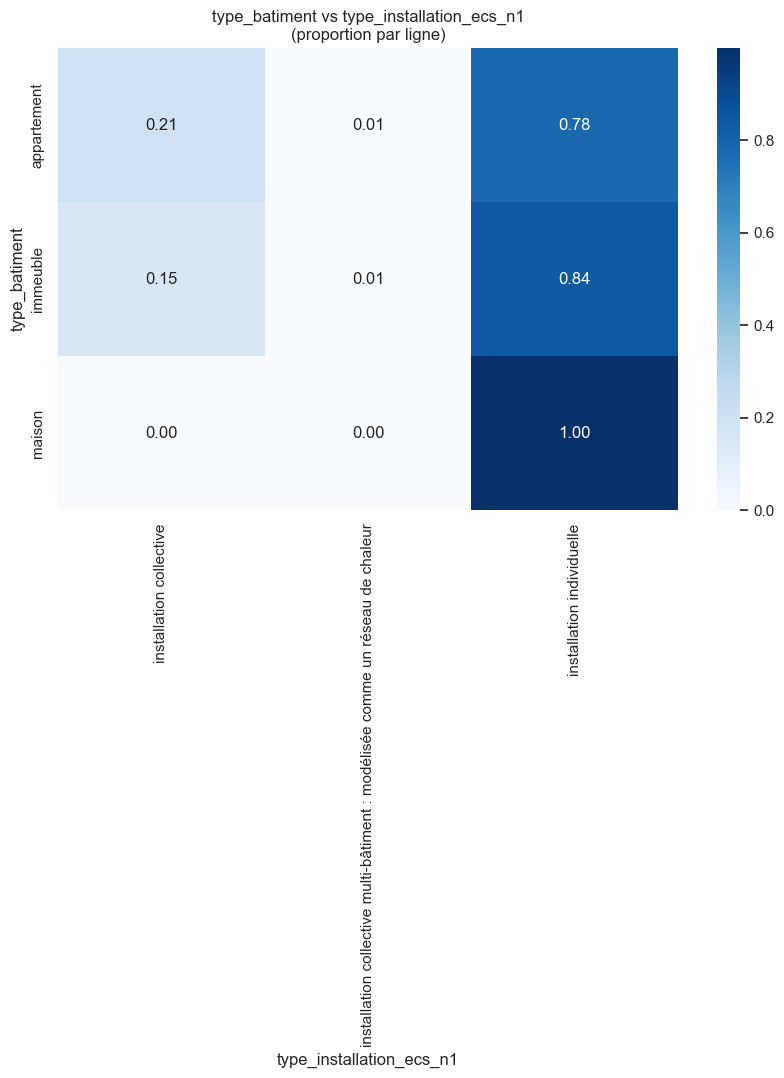

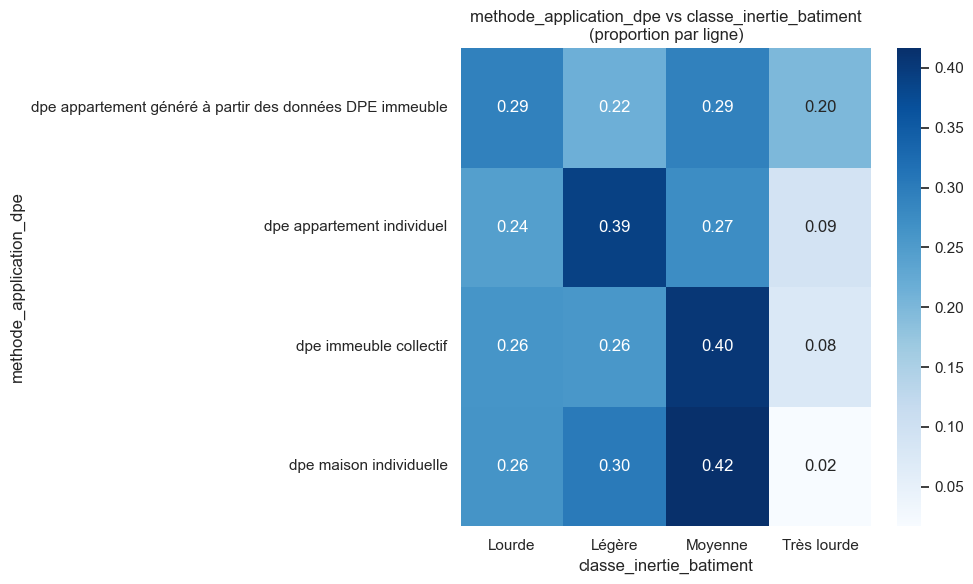

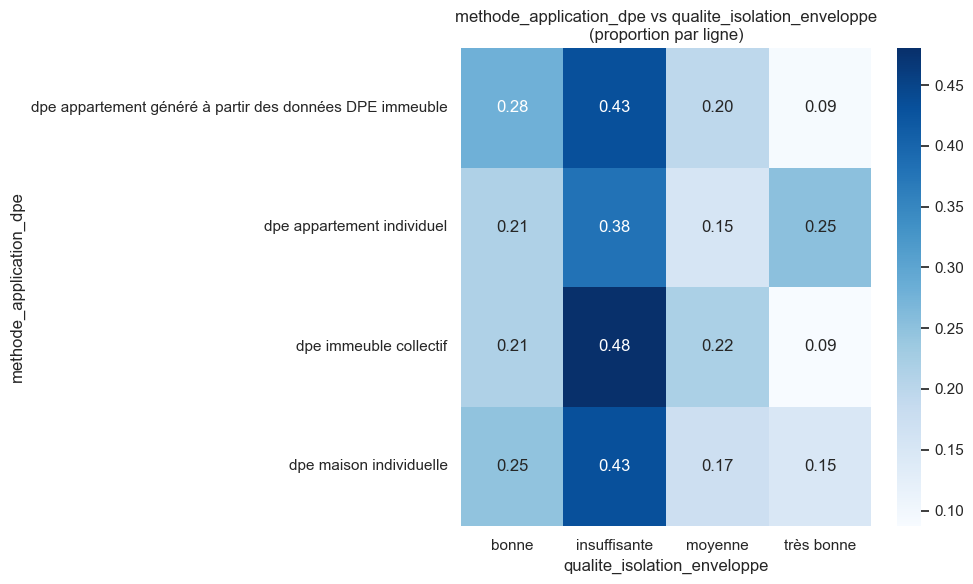

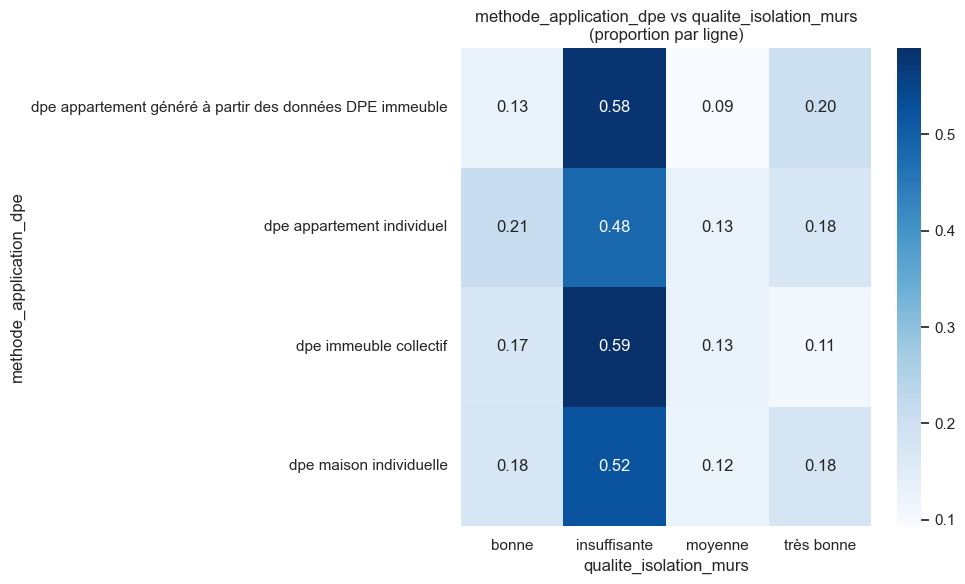

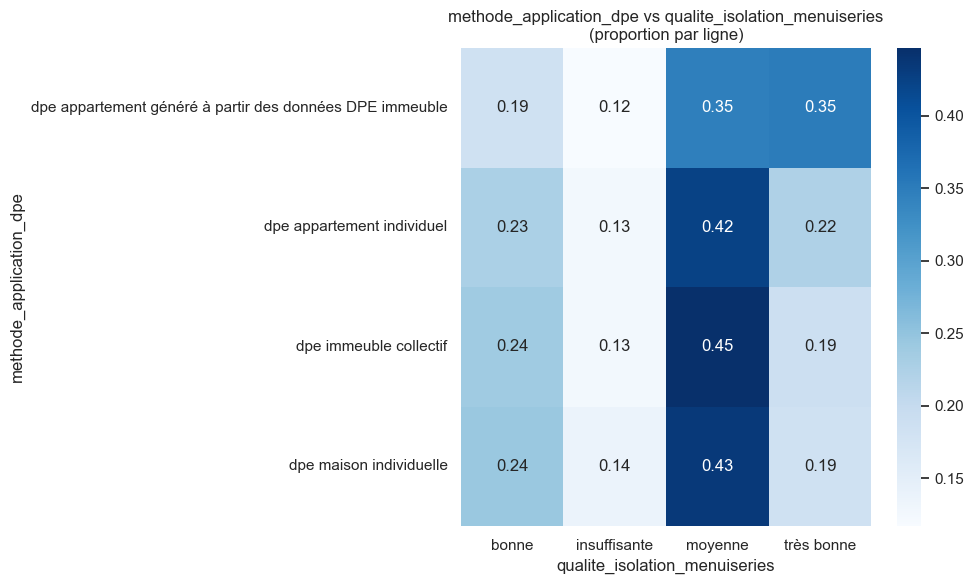

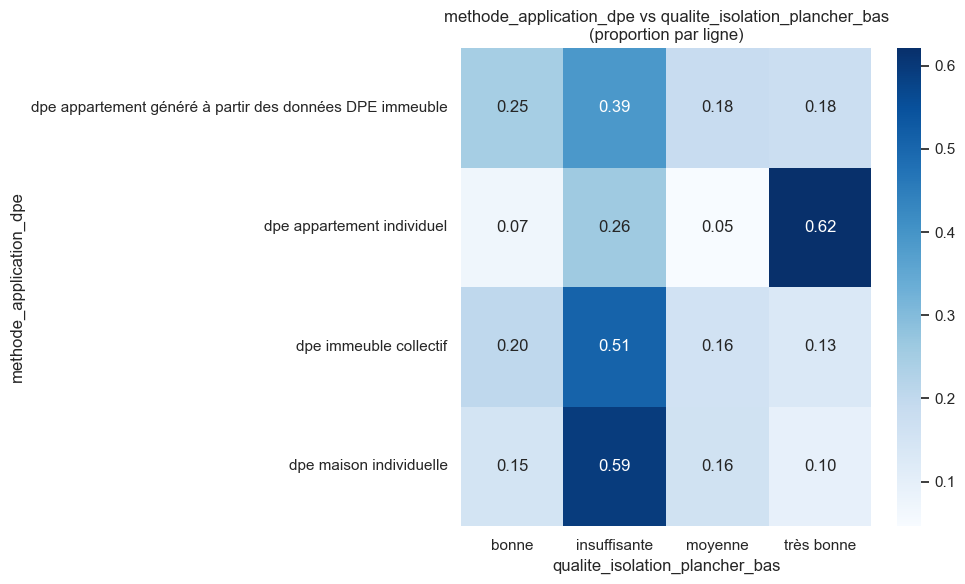

C:\Users\berul\AppData\Local\Temp\ipykernel_21244\3063194914.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


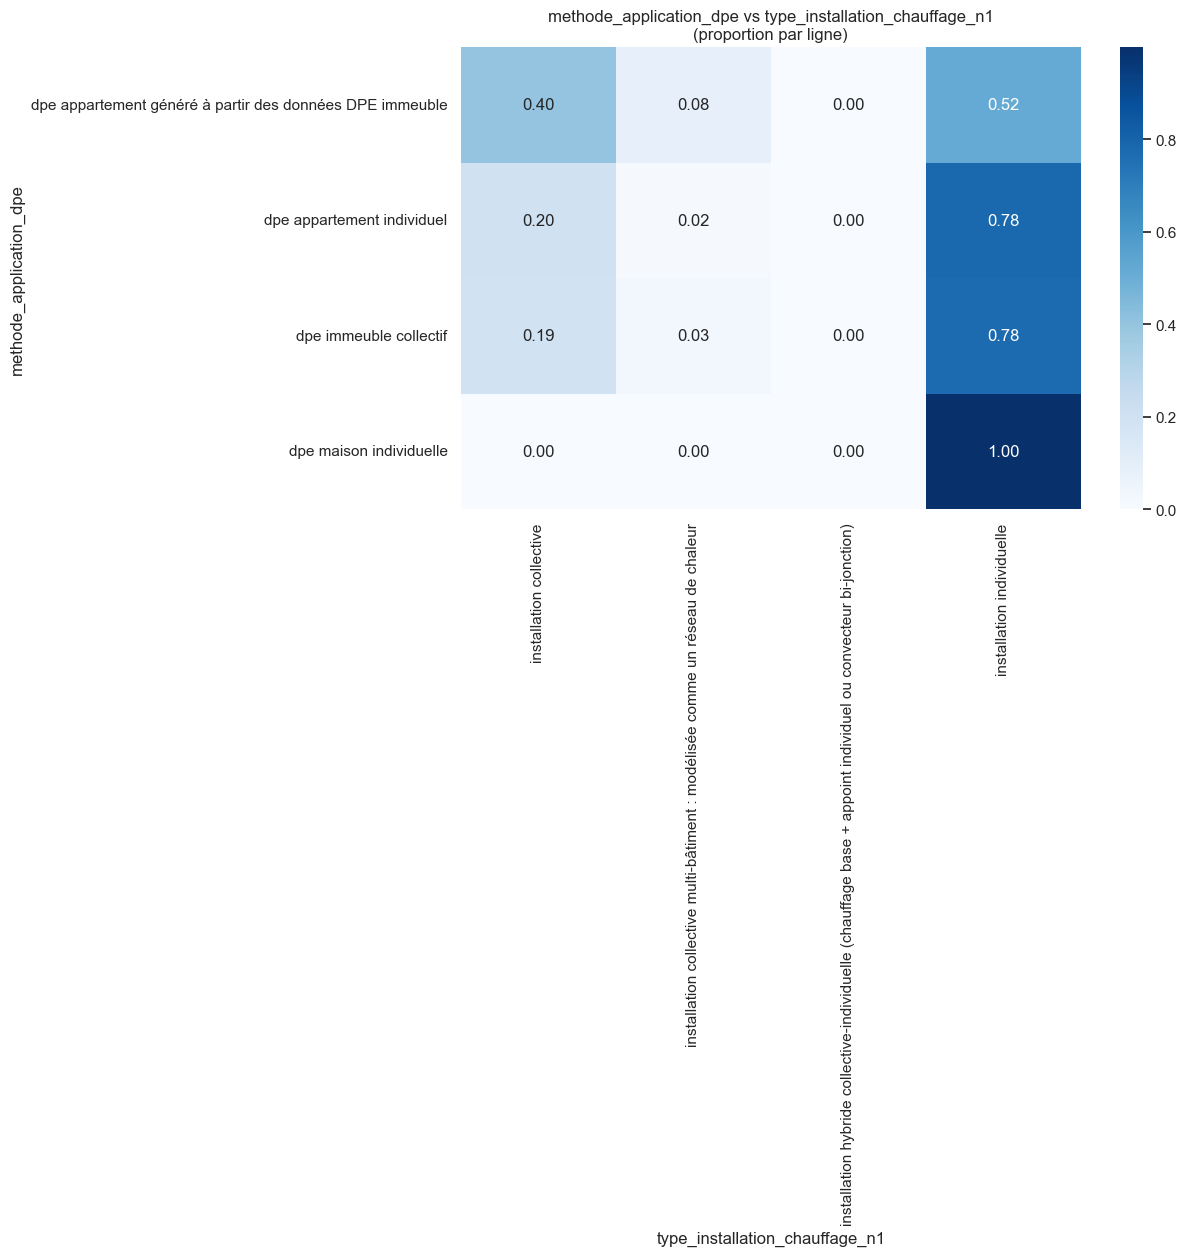

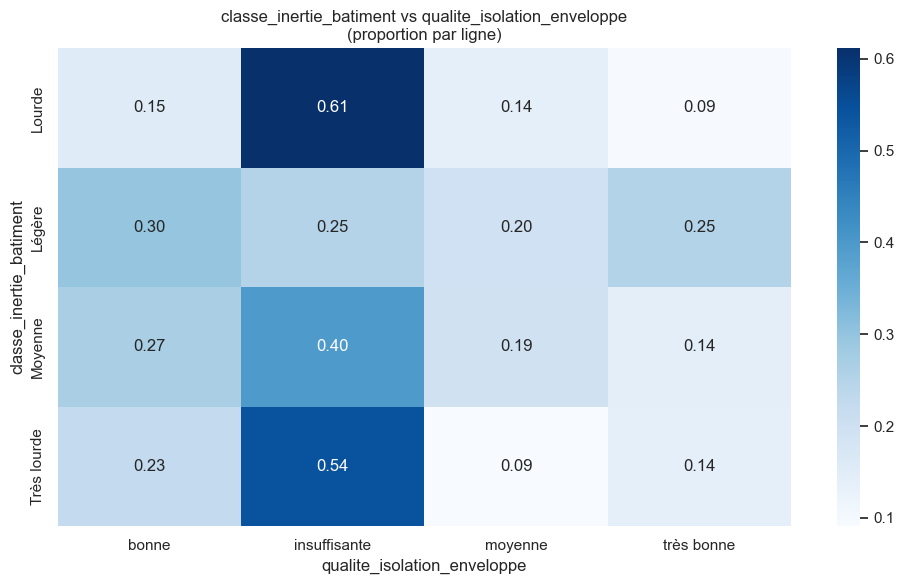

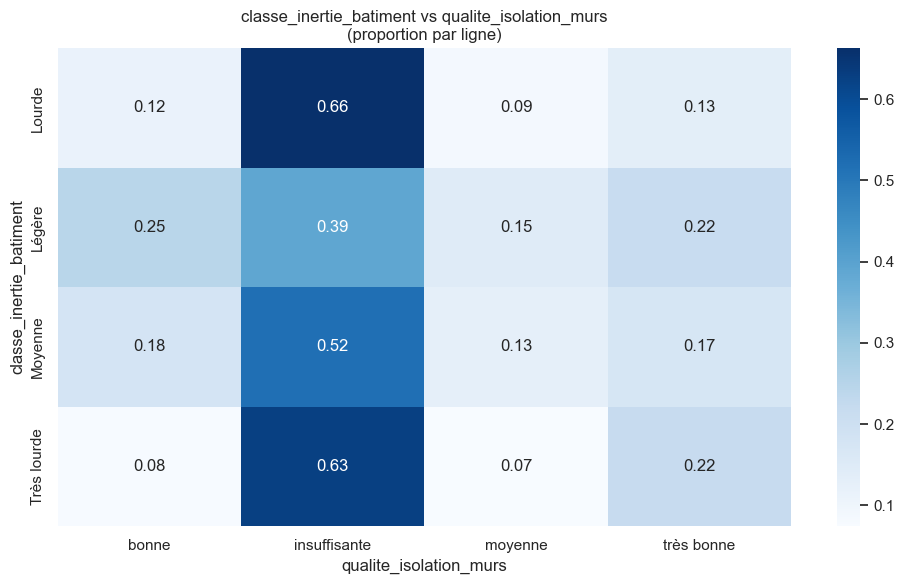

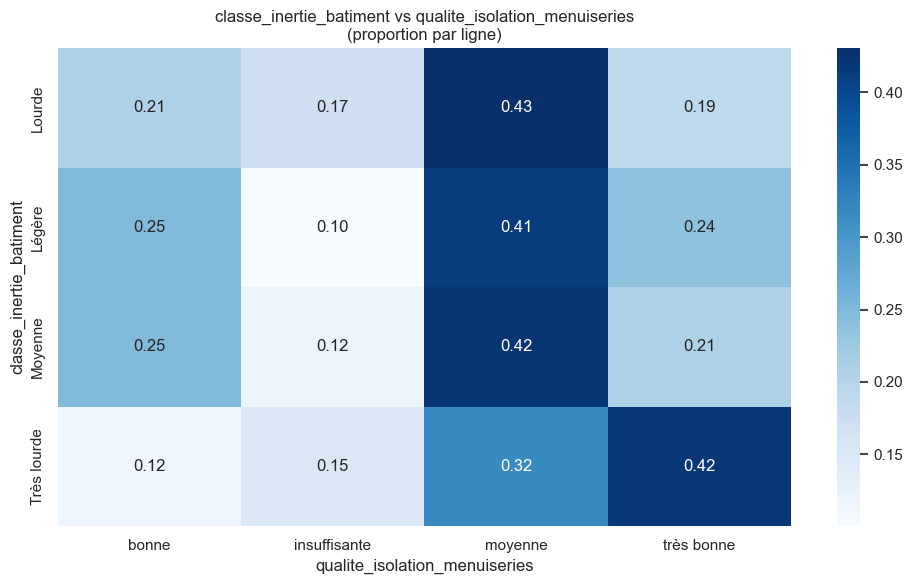

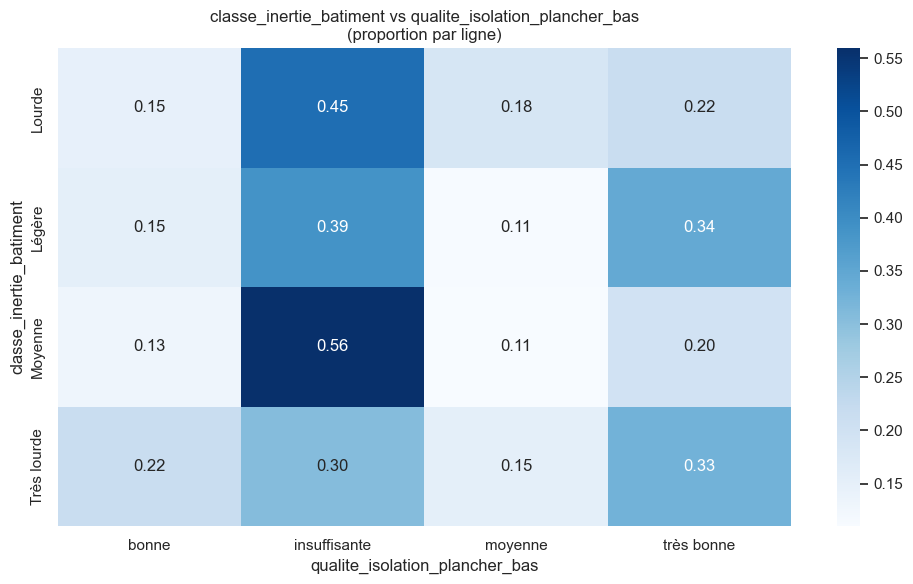

C:\Users\berul\AppData\Local\Temp\ipykernel_21244\3063194914.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


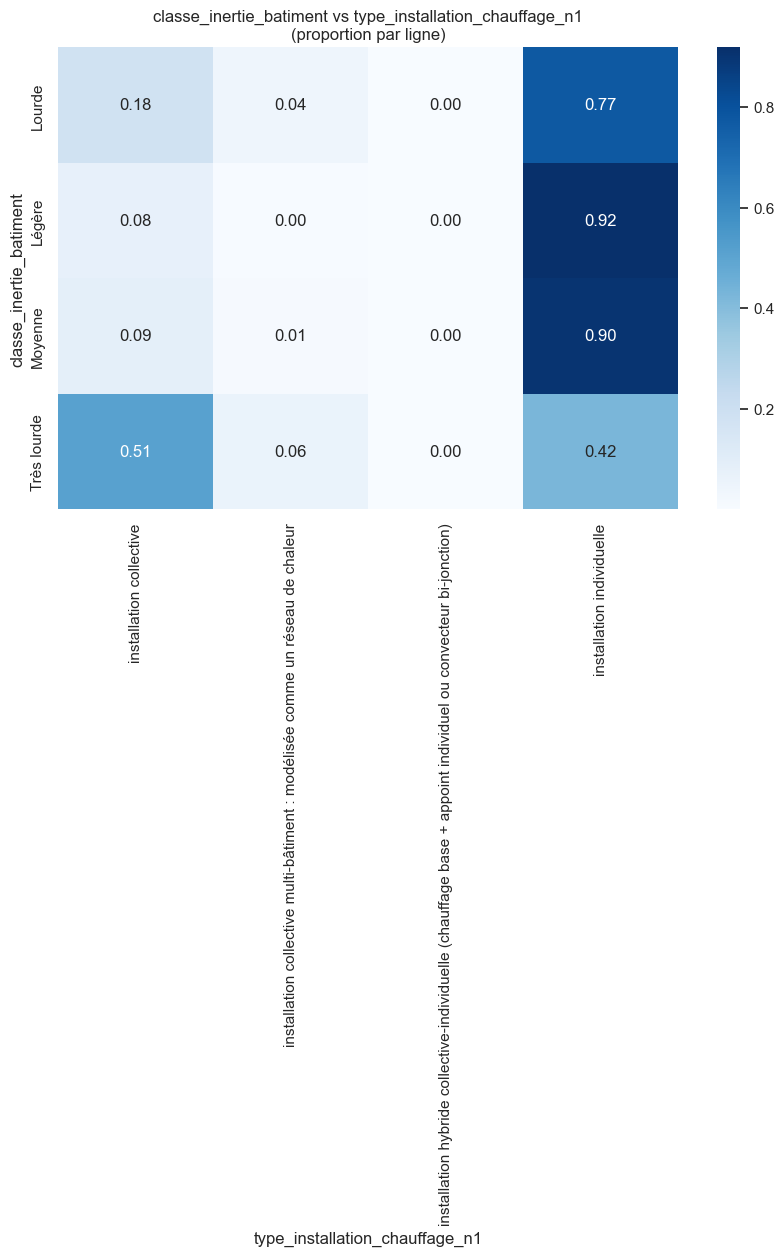

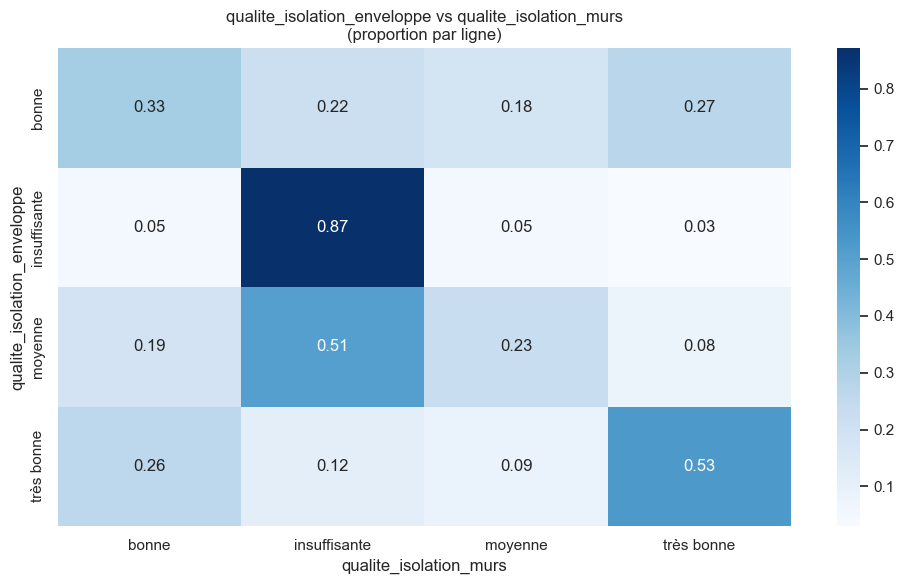

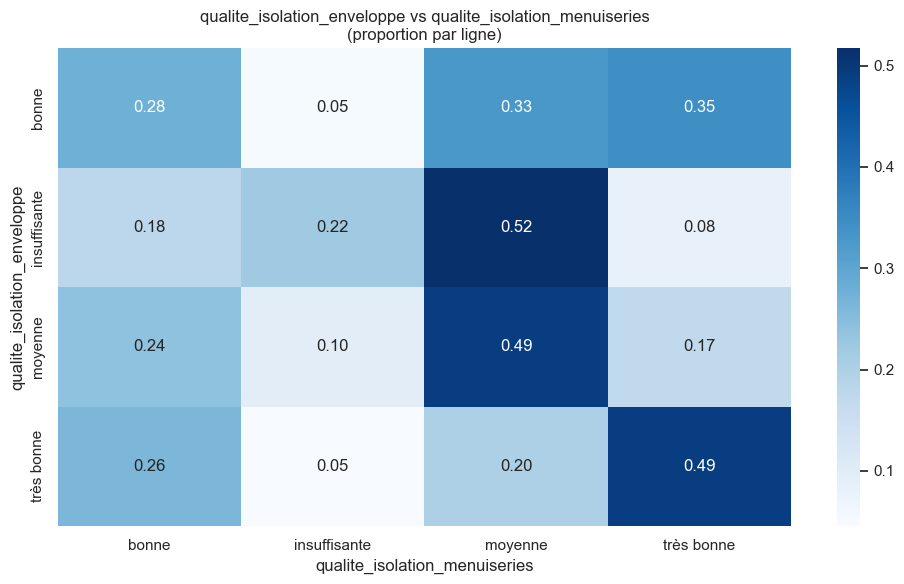

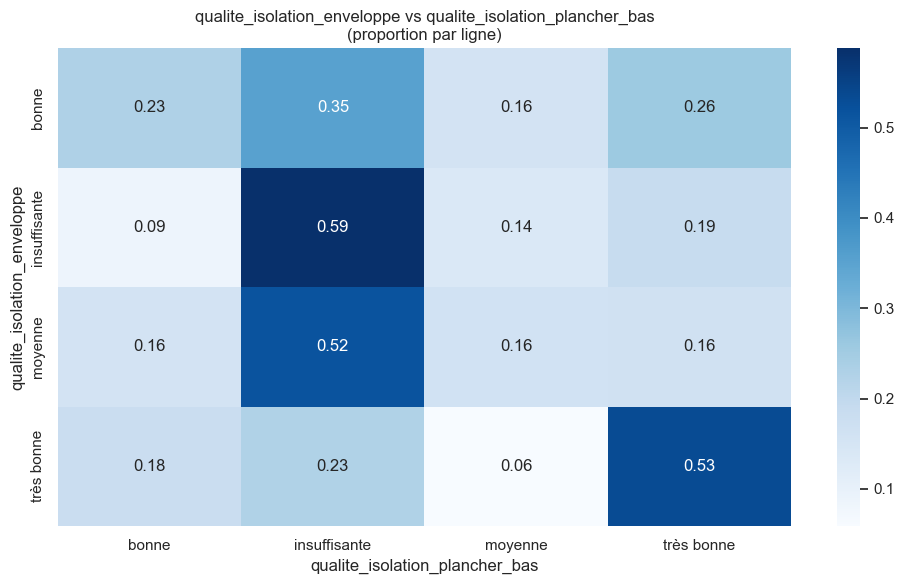

C:\Users\berul\AppData\Local\Temp\ipykernel_21244\3063194914.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


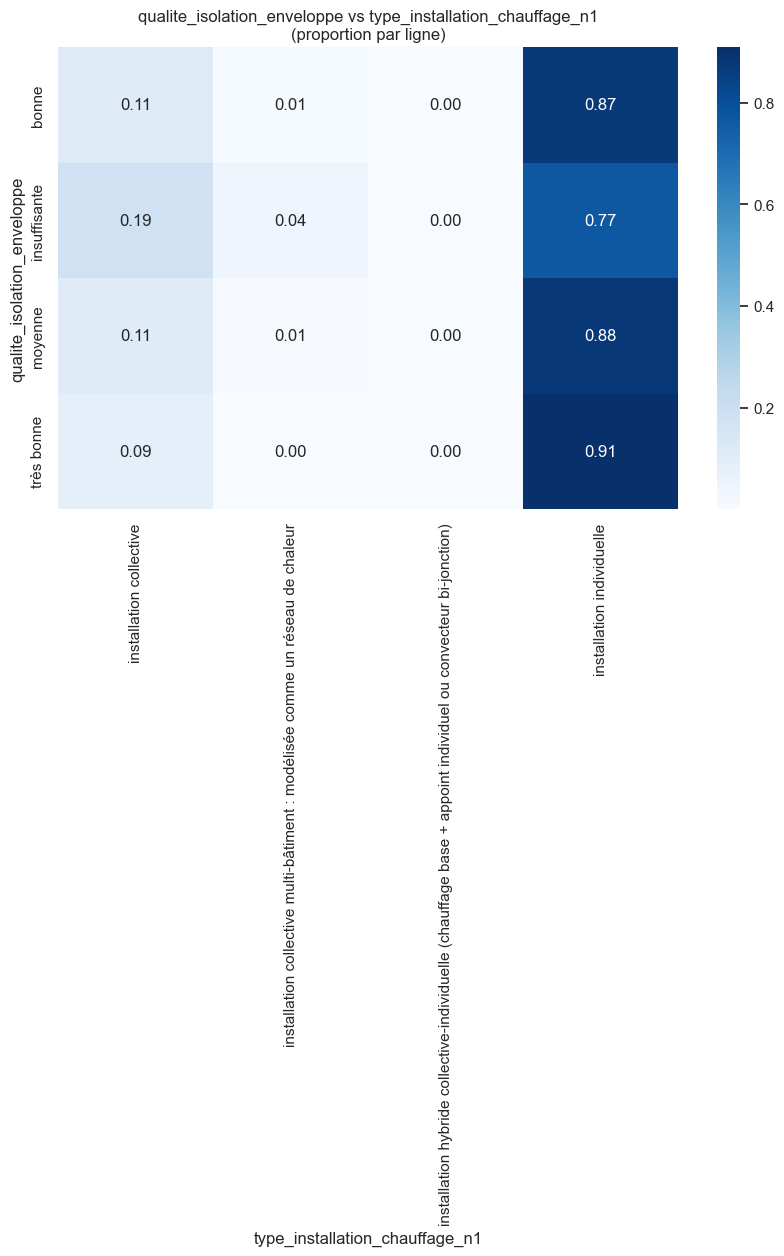

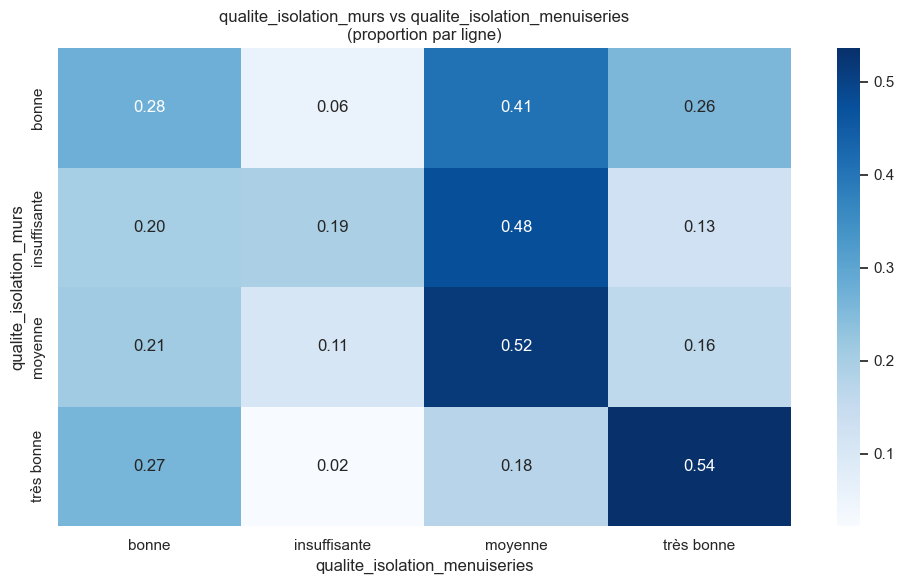

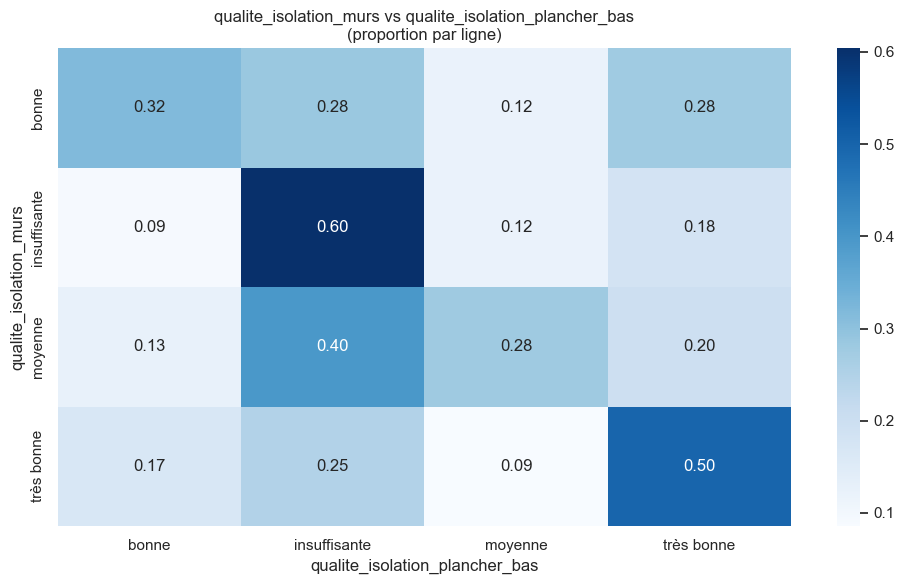

C:\Users\berul\AppData\Local\Temp\ipykernel_21244\3063194914.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


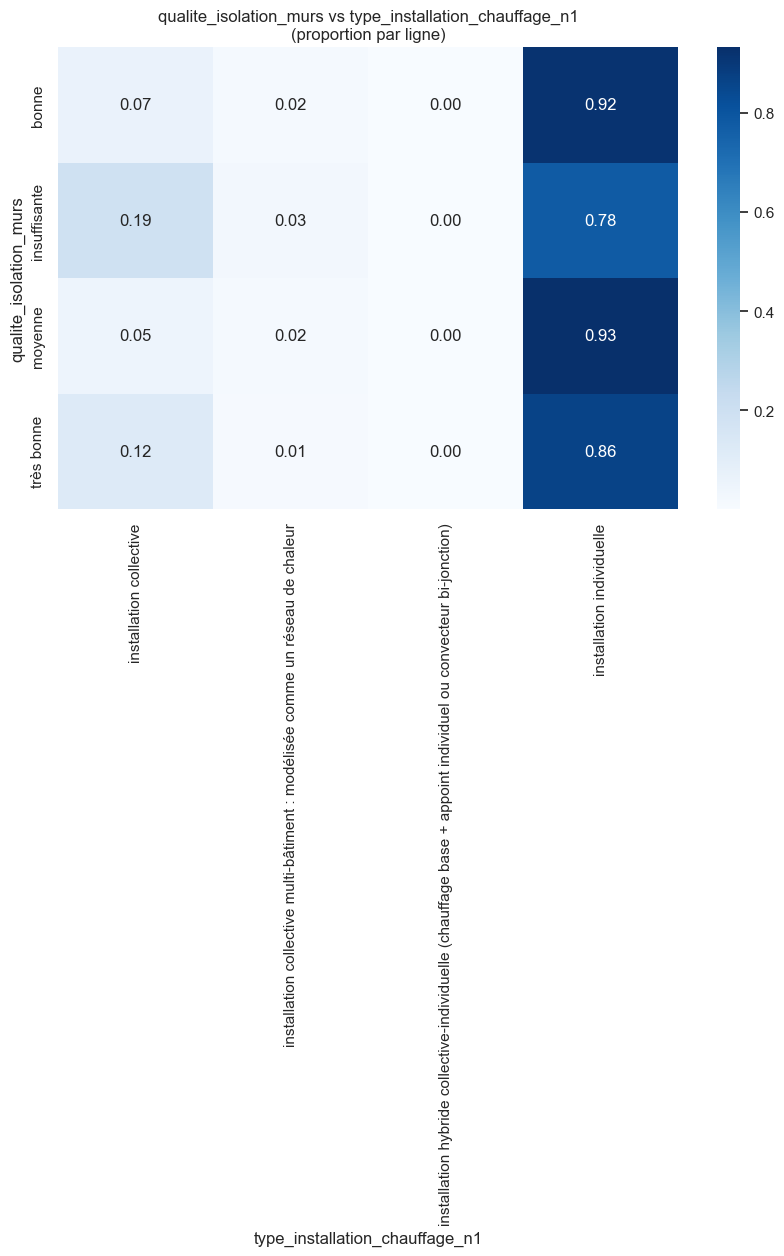

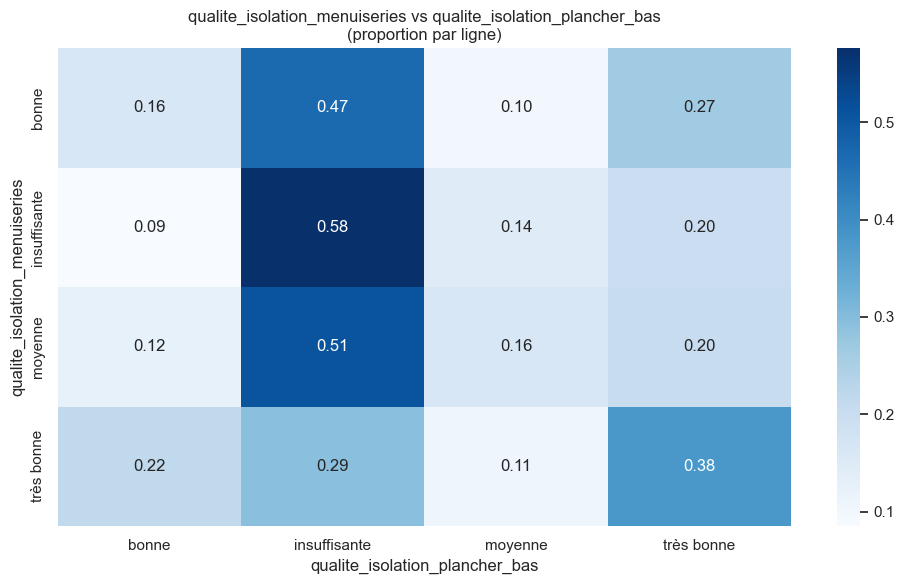

C:\Users\berul\AppData\Local\Temp\ipykernel_21244\3063194914.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


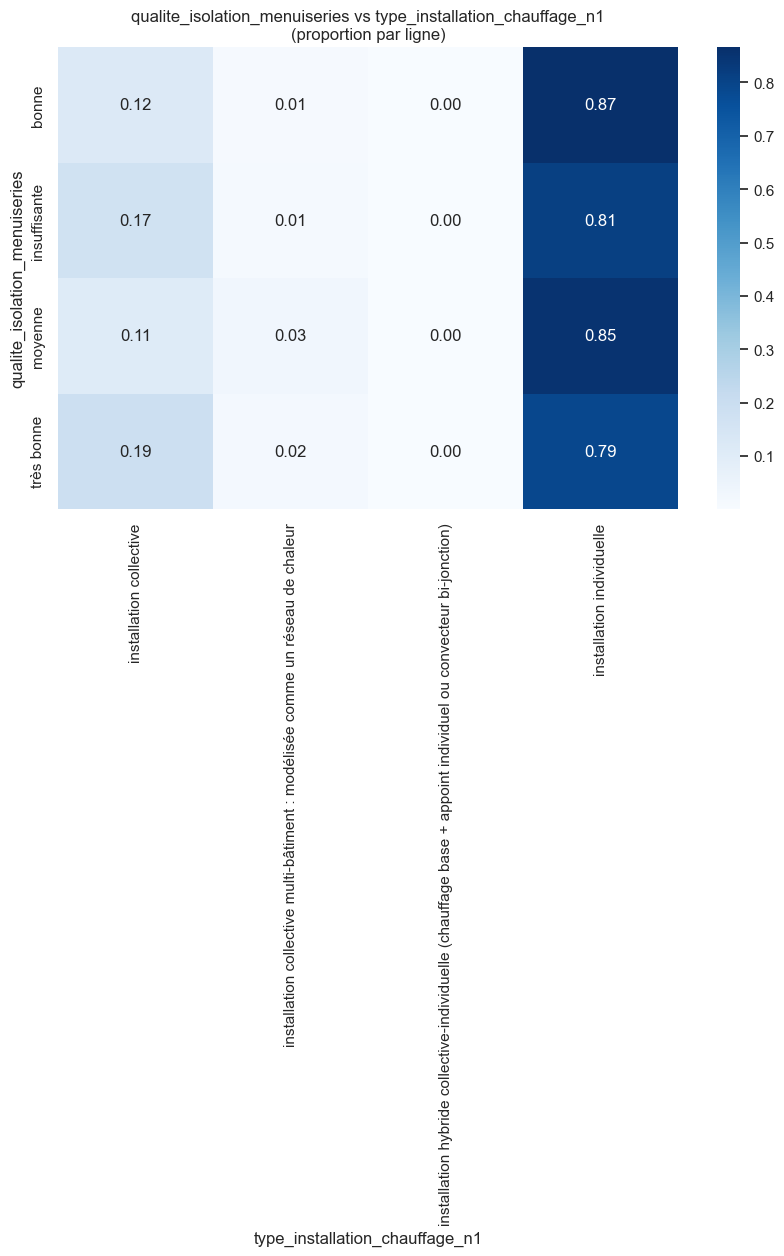

C:\Users\berul\AppData\Local\Temp\ipykernel_21244\3063194914.py:9: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


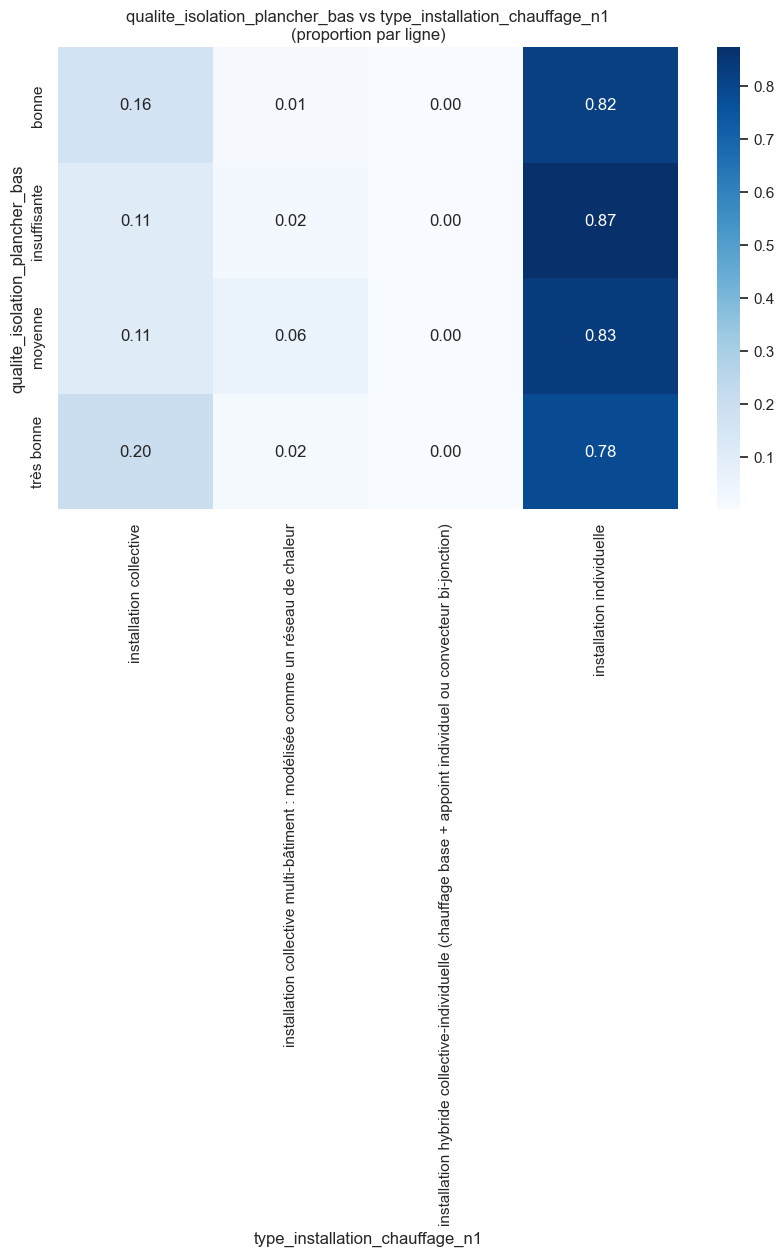

C:\Users\berul\AppData\Local\Temp\ipykernel_21244\3063194914.py:9: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


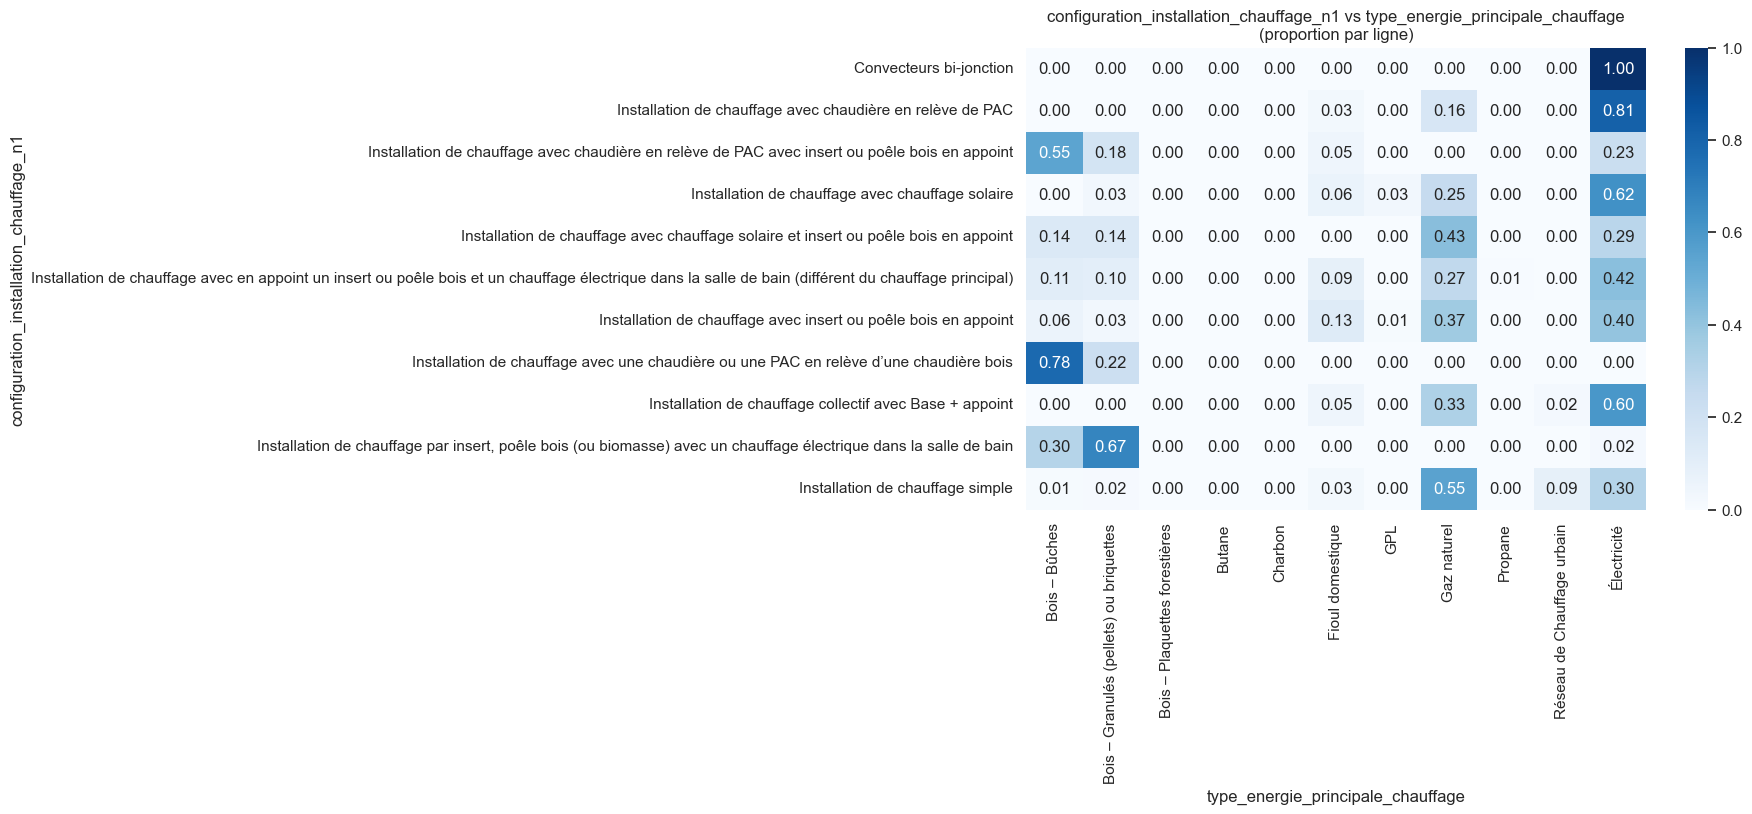

C:\Users\berul\AppData\Local\Temp\ipykernel_21244\3063194914.py:9: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


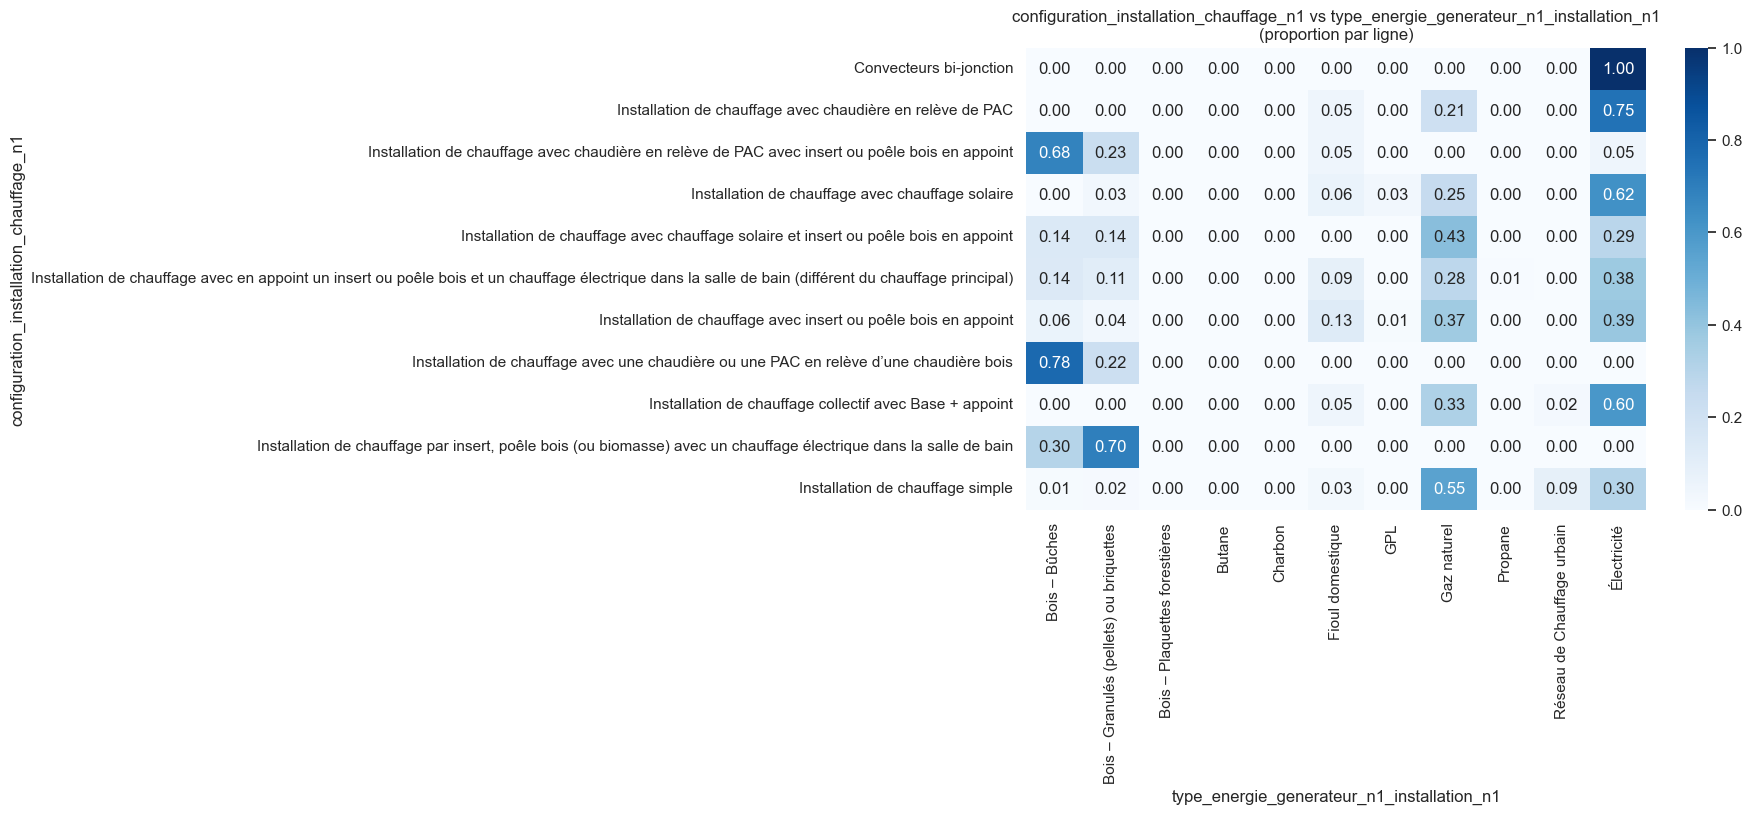

C:\Users\berul\AppData\Local\Temp\ipykernel_21244\3063194914.py:9: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


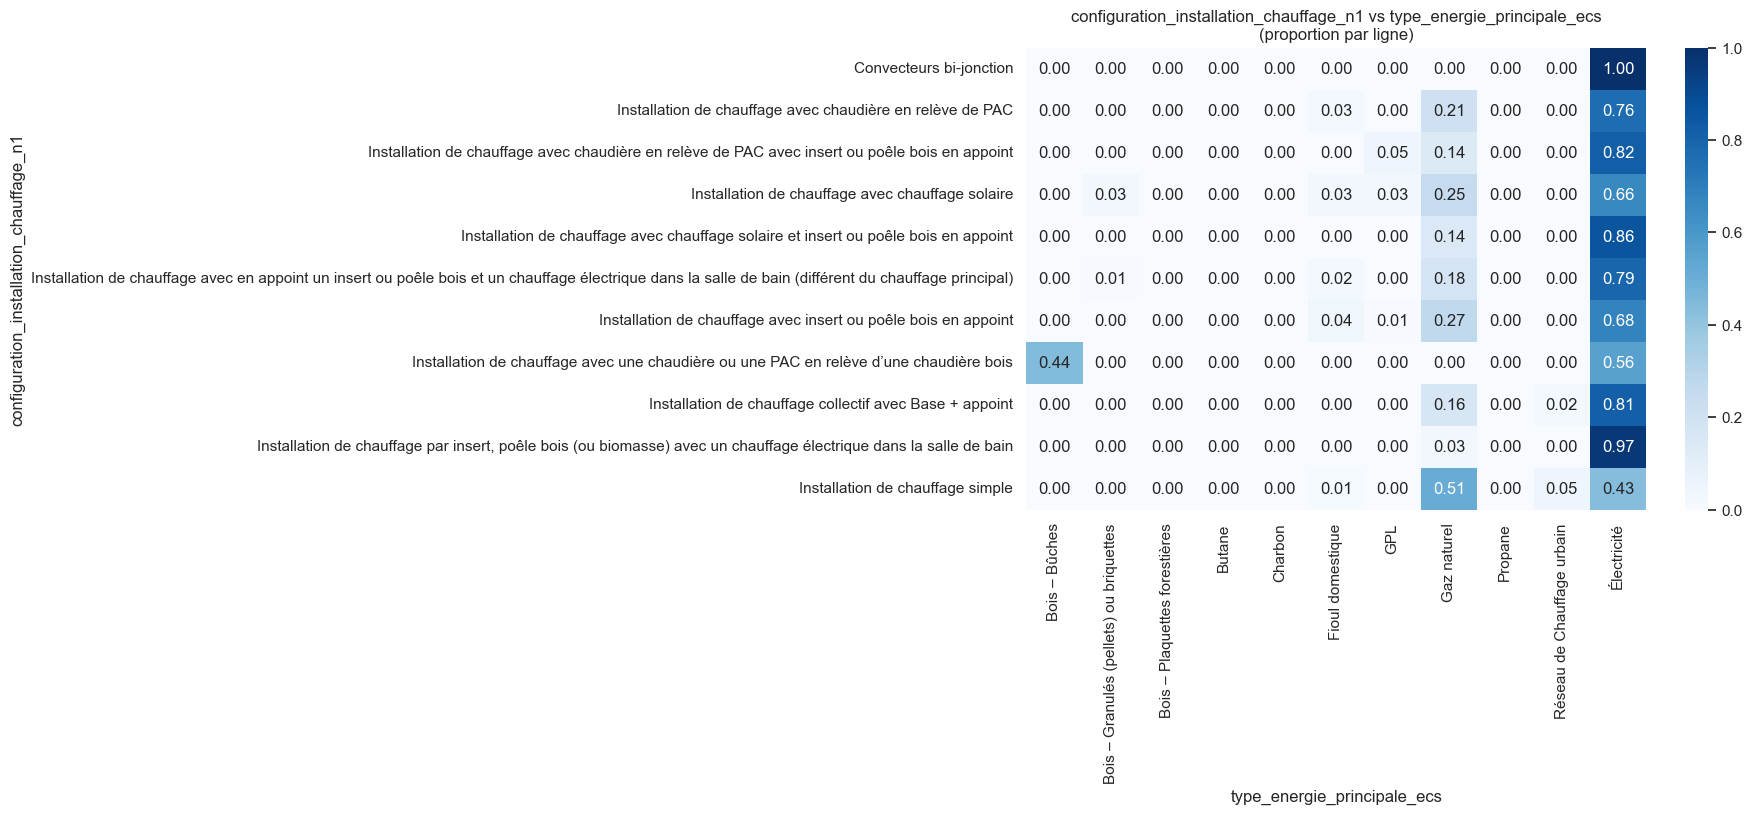

C:\Users\berul\AppData\Local\Temp\ipykernel_21244\3063194914.py:9: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


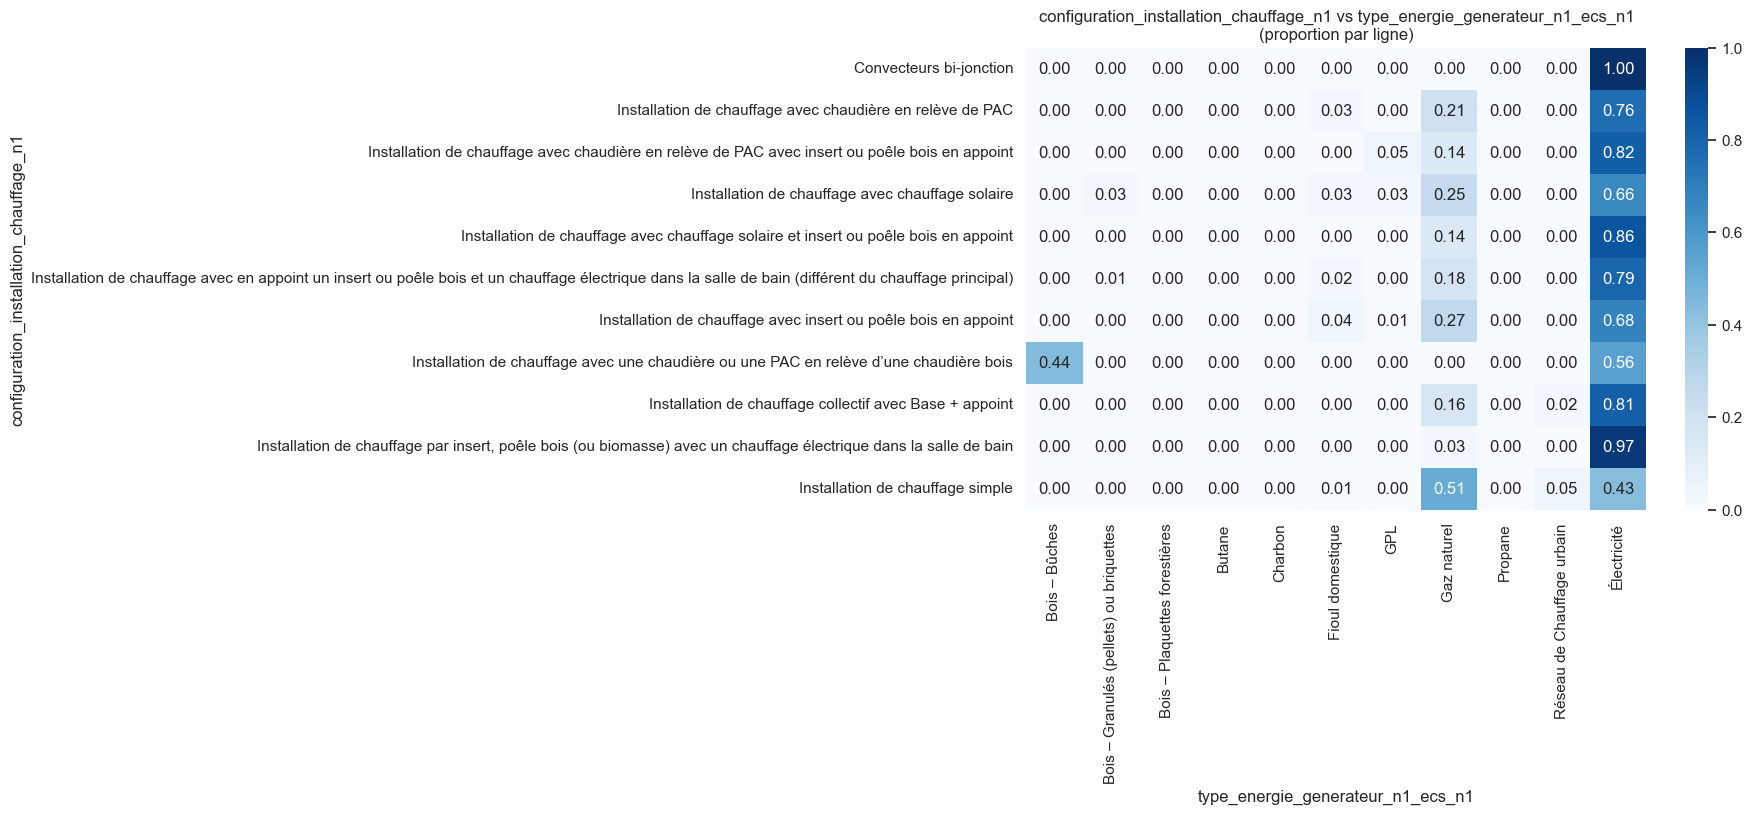

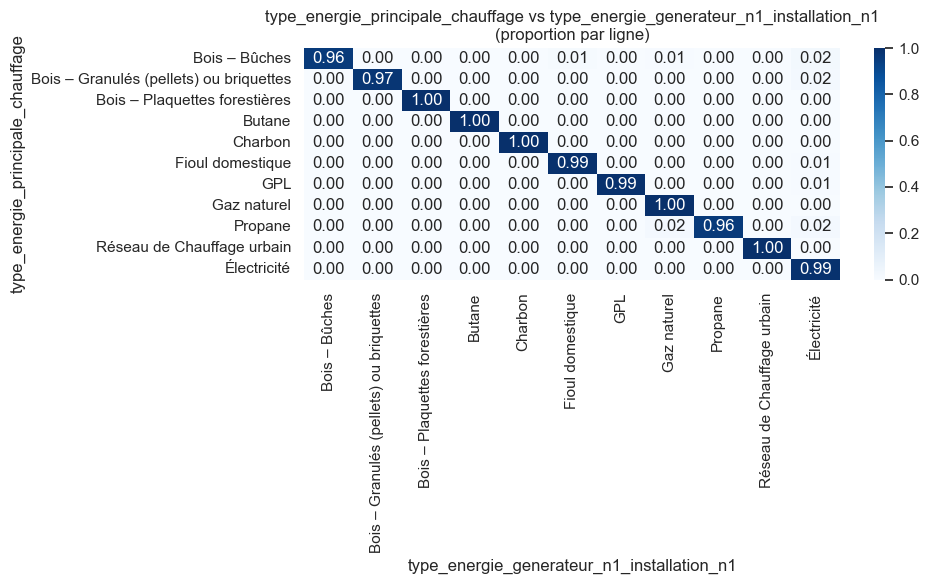

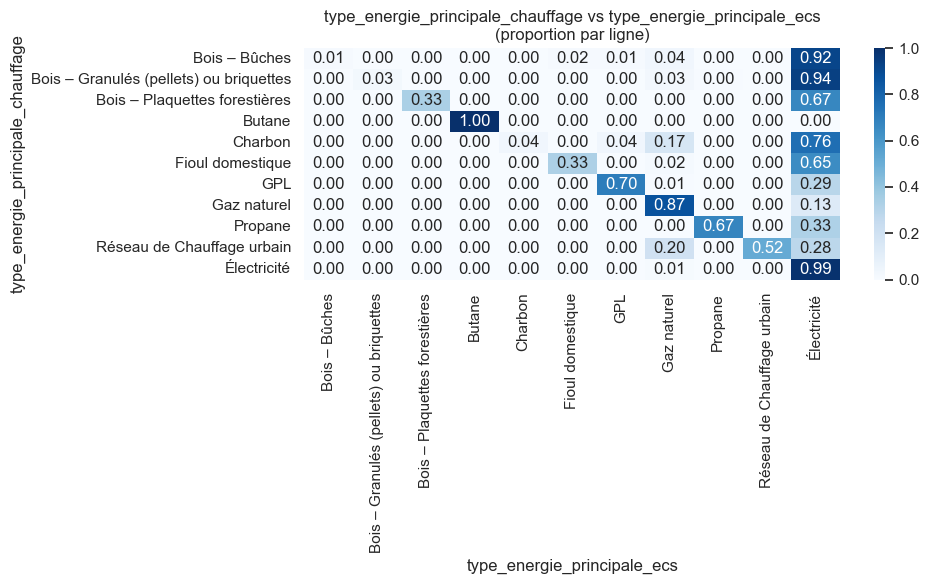

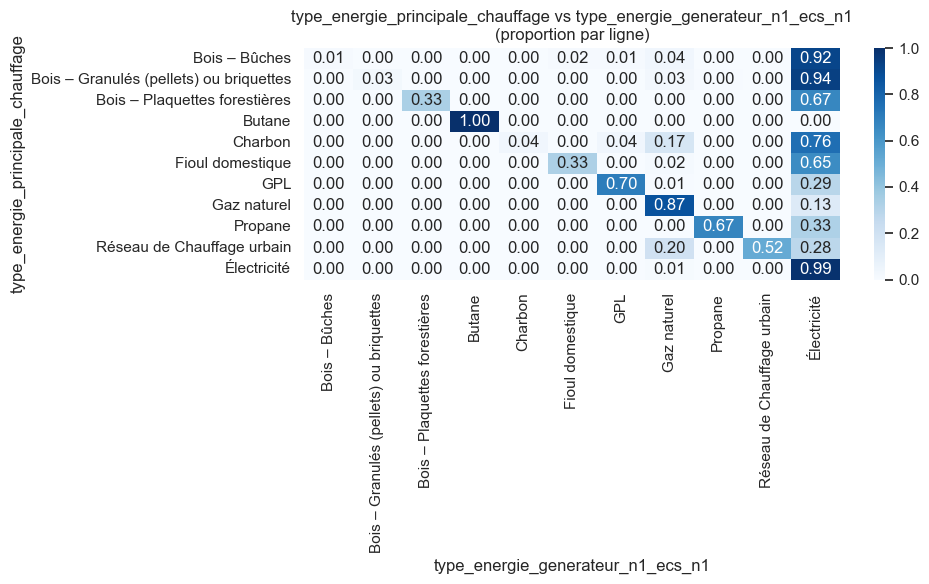

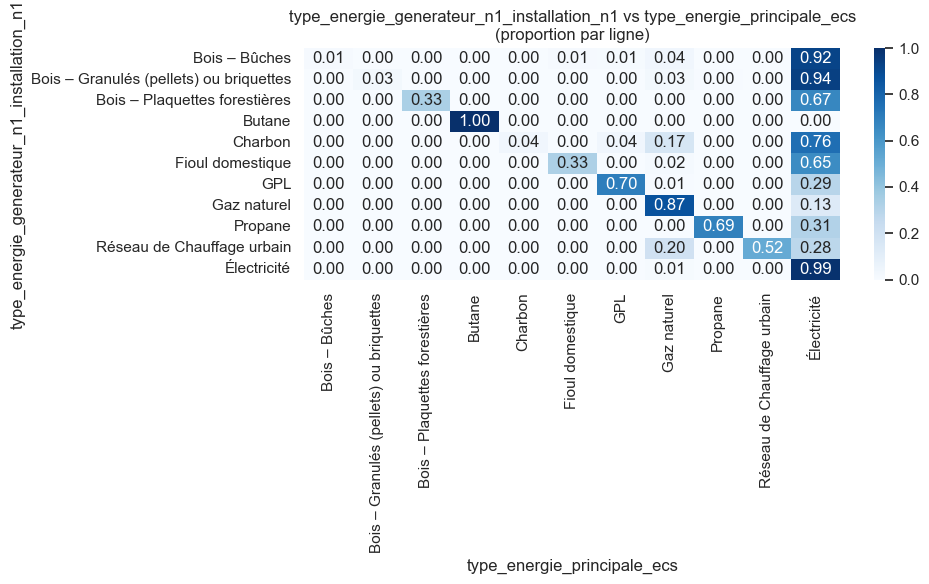

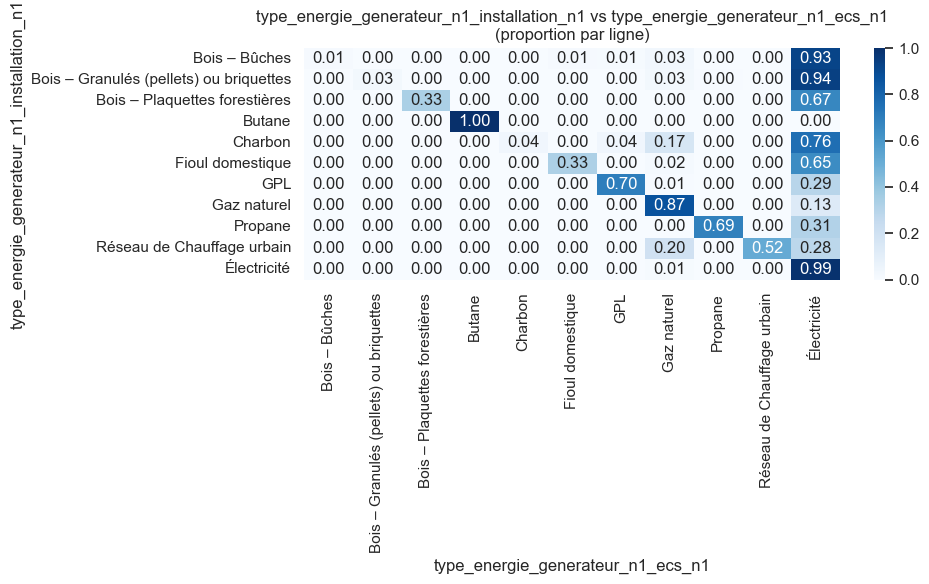

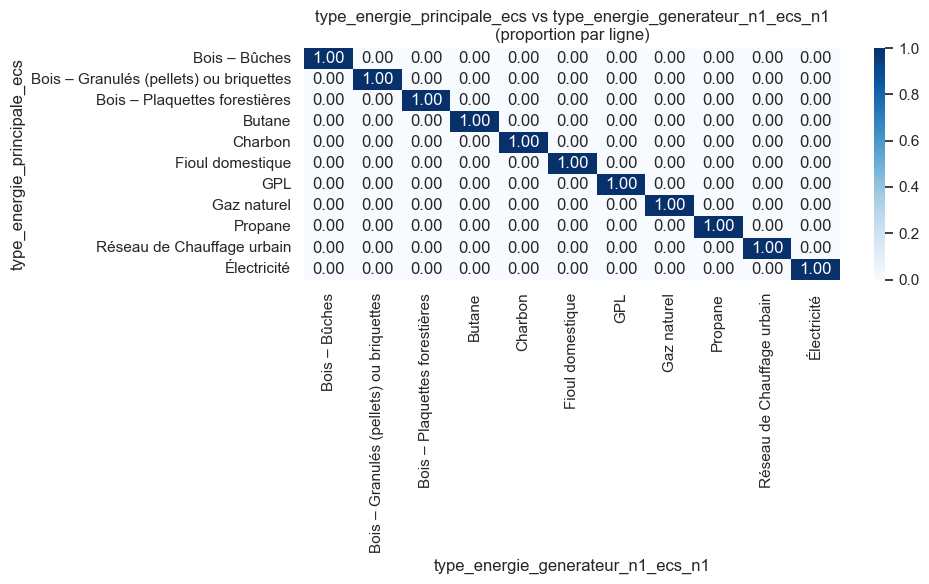

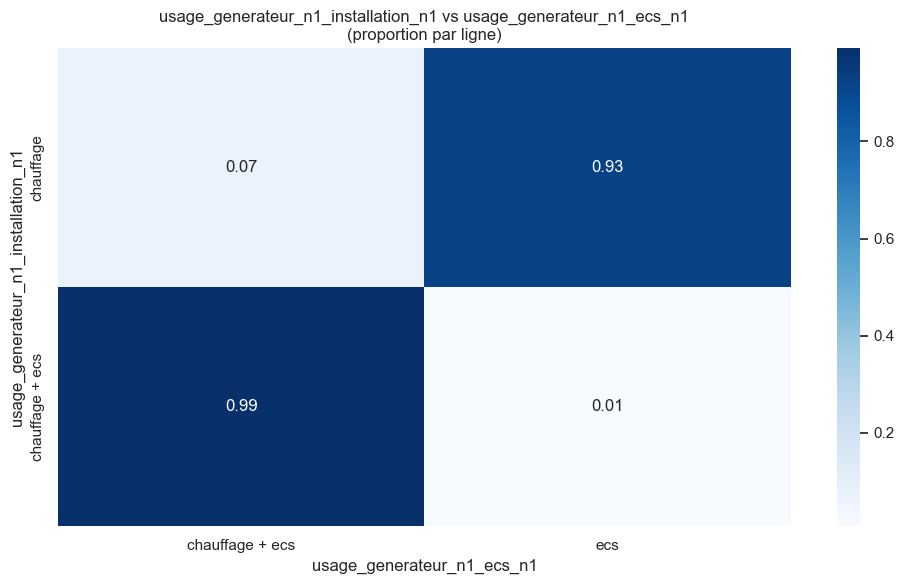

In [40]:
for k, cols in lots.items():
    if len(cols) < 2:
        continue
    for col1, col2 in itertools.combinations(cols, 2):
        table = pd.crosstab(df_data_clean[col1], df_data_clean[col2], normalize='index')
        plt.figure(figsize=(10, 6))
        sns.heatmap(table, annot=True, fmt=".2f", cmap="Blues")
        plt.title(f"{col1} vs {col2}\n(proportion par ligne)")
        plt.tight_layout()
        plt.show()

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Une forte correlation diagonale signifie que les deux variables encodent quasiment la meme
information (a chaque fois que X = A, alors Y = B) et que l'une des deux peut etre supprimee
sans perte d'information :

- `type_batiment` / `methode_application_dpe`
- `type_energie_principale_chauffage` / `type_energie_generateur_n1_installation_n1`
- `type_energie_principale_ecs` / `type_energie_generateur_n1_ecs_n1`
- `usage_generateur_n1_installation_n1` / `usage_generateur_n1_ecs_n1`

Les autres paires de meme cardinalite apportent une information complementaire et sont
conservees.

In [41]:
suppr_redondance = [
    "methode_application_dpe",
    "type_energie_generateur_n1_installation_n1",
    "type_energie_generateur_n1_ecs_n1",
    "usage_generateur_n1_ecs_n1",
]
suppr_redondance = [c for c in suppr_redondance if c in df_data_clean.columns]
print(f"Colonnes marquees pour suppression (redondance) : {suppr_redondance}")

Colonnes marquees pour suppression (redondance) : ['methode_application_dpe', 'type_energie_generateur_n1_installation_n1', 'type_energie_generateur_n1_ecs_n1', 'usage_generateur_n1_ecs_n1']


## 7. Agregation des variables categorielles

Certaines variables comportent de nombreuses modalites peu frequentes. On les regroupe en
categories plus larges et coherentes, en s'appuyant sur la repartition de l'etiquette DPE
par modalite et un clustering hierarchique pour identifier les modalites similaires.

### 7.1 Periode de construction

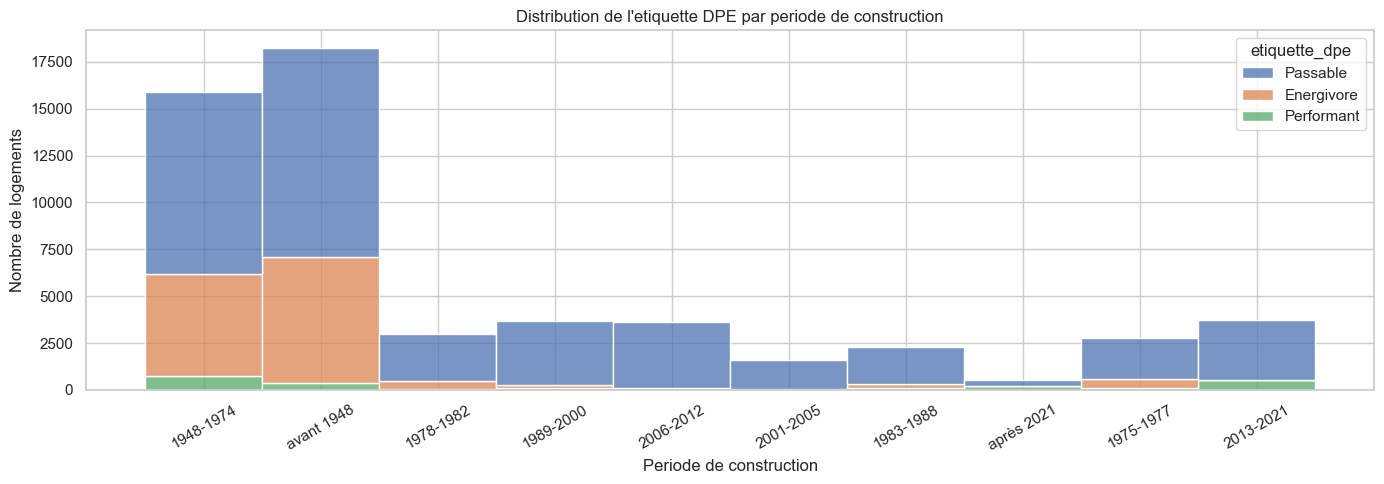

In [42]:
plt.figure(figsize=(14, 5))
sns.histplot(data=df_data_clean, x="periode_construction", hue="etiquette_dpe", multiple="stack")
plt.title("Distribution de l'etiquette DPE par periode de construction")
plt.xlabel("Periode de construction")
plt.ylabel("Nombre de logements")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [43]:
tab_periode = pd.crosstab(
    df_data_clean["periode_construction"],
    df_data_clean["etiquette_dpe"],
    normalize="index"
)
tab_periode.round(3)

etiquette_dpe,Energivore,Passable,Performant
periode_construction,,,
1948-1974,0.341,0.612,0.047
1975-1977,0.156,0.798,0.046
1978-1982,0.145,0.832,0.024
1983-1988,0.111,0.854,0.035
1989-2000,0.046,0.930,0.024
2001-2005,0.021,0.965,0.014
2006-2012,0.006,0.966,0.028
2013-2021,0.003,0.857,0.140
après 2021,0.002,0.633,0.365


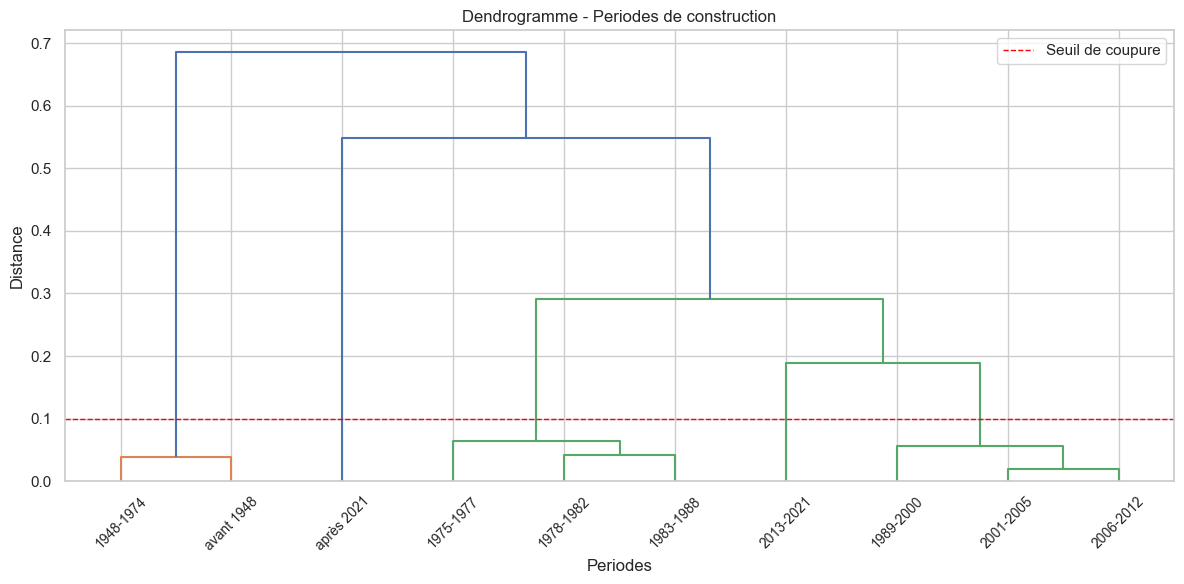

In [44]:
Z = linkage(tab_periode, method='ward')

plt.figure(figsize=(12, 6))
dendrogram(Z, labels=tab_periode.index.tolist(), leaf_rotation=45, leaf_font_size=10)
plt.axhline(y=0.1, color='red', linestyle='--', linewidth=1, label='Seuil de coupure')
plt.title("Dendrogramme - Periodes de construction")
plt.xlabel("Periodes")
plt.ylabel("Distance")
plt.legend()
plt.tight_layout()
plt.show()

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Le dendrogramme revele des groupes coherents de periodes de construction, qui correspondent
globalement aux evolutions des reglementations thermiques (avant 1948, 1948-1988, 1989-2012,
apres 2012). Ce regroupement reduit la cardinalite de 10 a 5 modalites tout en conservant le
pouvoir discriminant sur l'etiquette DPE.

### 7.2 Configuration de l'installation de chauffage

C:\Users\berul\AppData\Local\Temp\ipykernel_21244\626966644.py:7: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


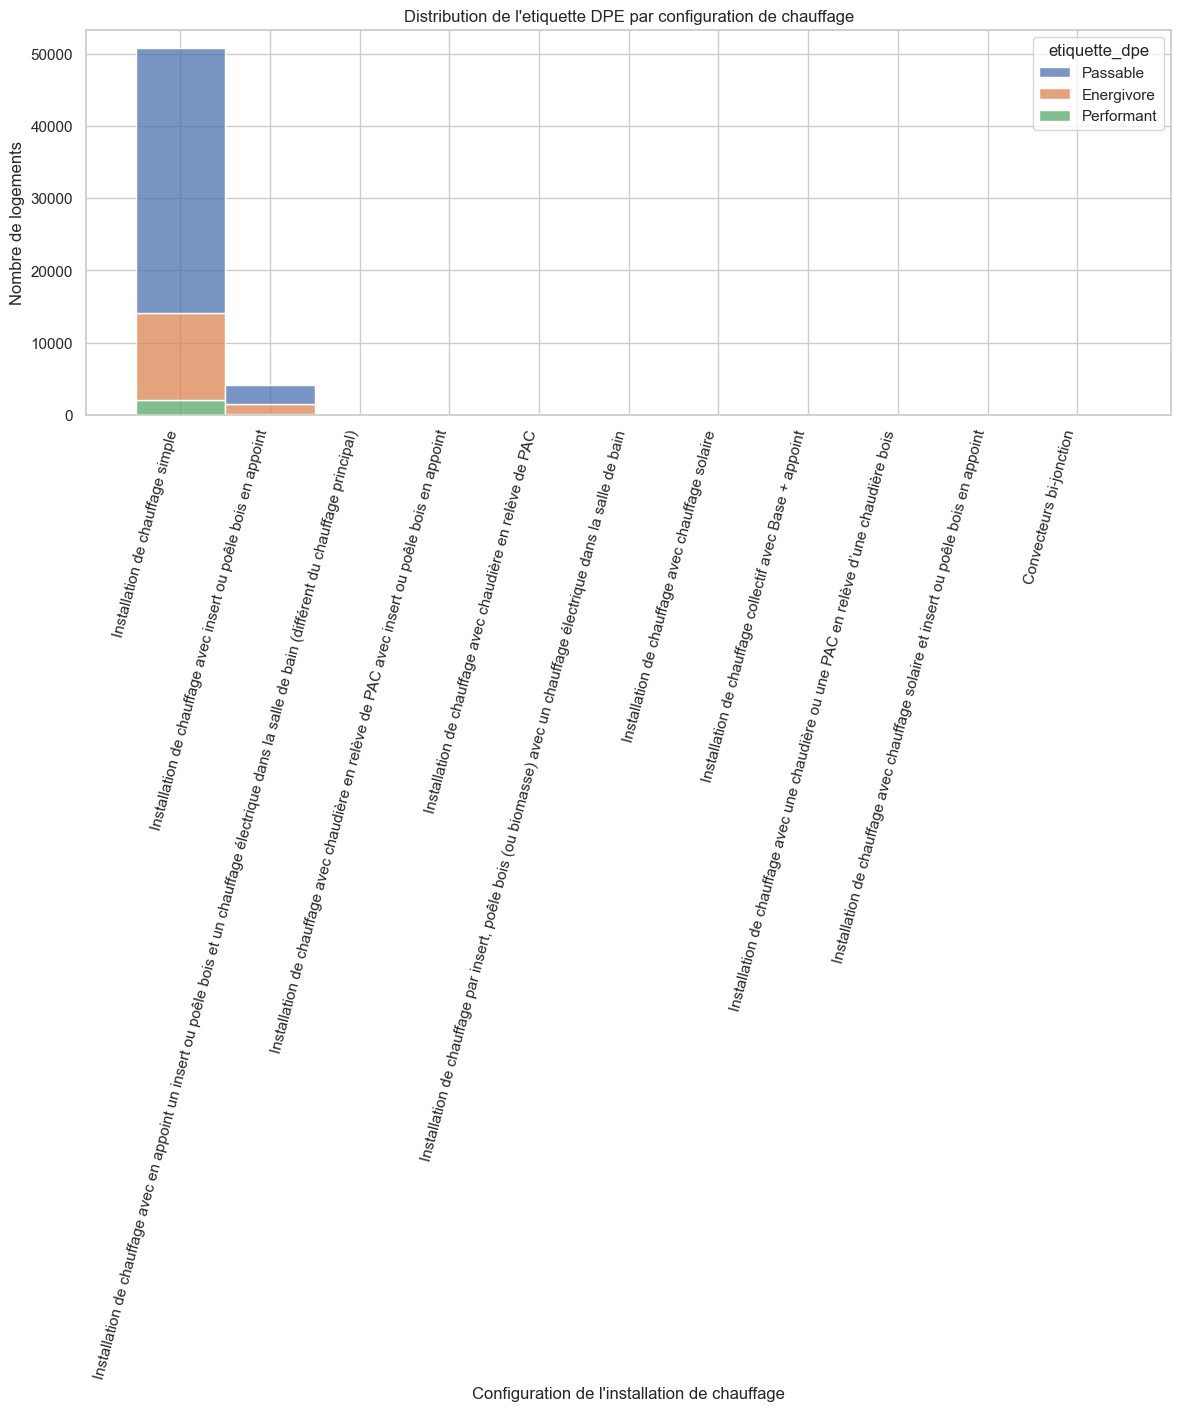

In [45]:
plt.figure(figsize=(14, 5))
sns.histplot(data=df_data_clean, x="configuration_installation_chauffage_n1", hue="etiquette_dpe", multiple="stack")
plt.title("Distribution de l'etiquette DPE par configuration de chauffage")
plt.xlabel("Configuration de l'installation de chauffage")
plt.ylabel("Nombre de logements")
plt.xticks(rotation=75, ha='right')
plt.tight_layout()
plt.show()

In [46]:
tab_conf_install = pd.crosstab(
    df_data_clean["configuration_installation_chauffage_n1"],
    df_data_clean["etiquette_dpe"],
    normalize="index"
)
tab_conf_install.round(3)

etiquette_dpe,Energivore,Passable,Performant
configuration_installation_chauffage_n1,,,
Convecteurs bi-jonction,0.500,0.500,0.000
Installation de chauffage avec chaudière en relève de PAC,0.036,0.509,0.455
Installation de chauffage avec chaudière en relève de PAC avec insert ou poêle bois en appoint,0.045,0.773,0.182
Installation de chauffage avec chauffage solaire,0.062,0.281,0.656
Installation de chauffage avec chauffage solaire et insert ou poêle bois en appoint,0.000,0.857,0.143
Installation de chauffage avec en appoint un insert ou poêle bois et un chauffage électrique dans la salle de bain (différent du chauffage principal),0.274,0.673,0.054
Installation de chauffage avec insert ou poêle bois en appoint,0.343,0.624,0.033
Installation de chauffage avec une chaudière ou une PAC en relève d’une chaudière bois,0.667,0.222,0.111
Installation de chauffage collectif avec Base + appoint,0.302,0.674,0.023


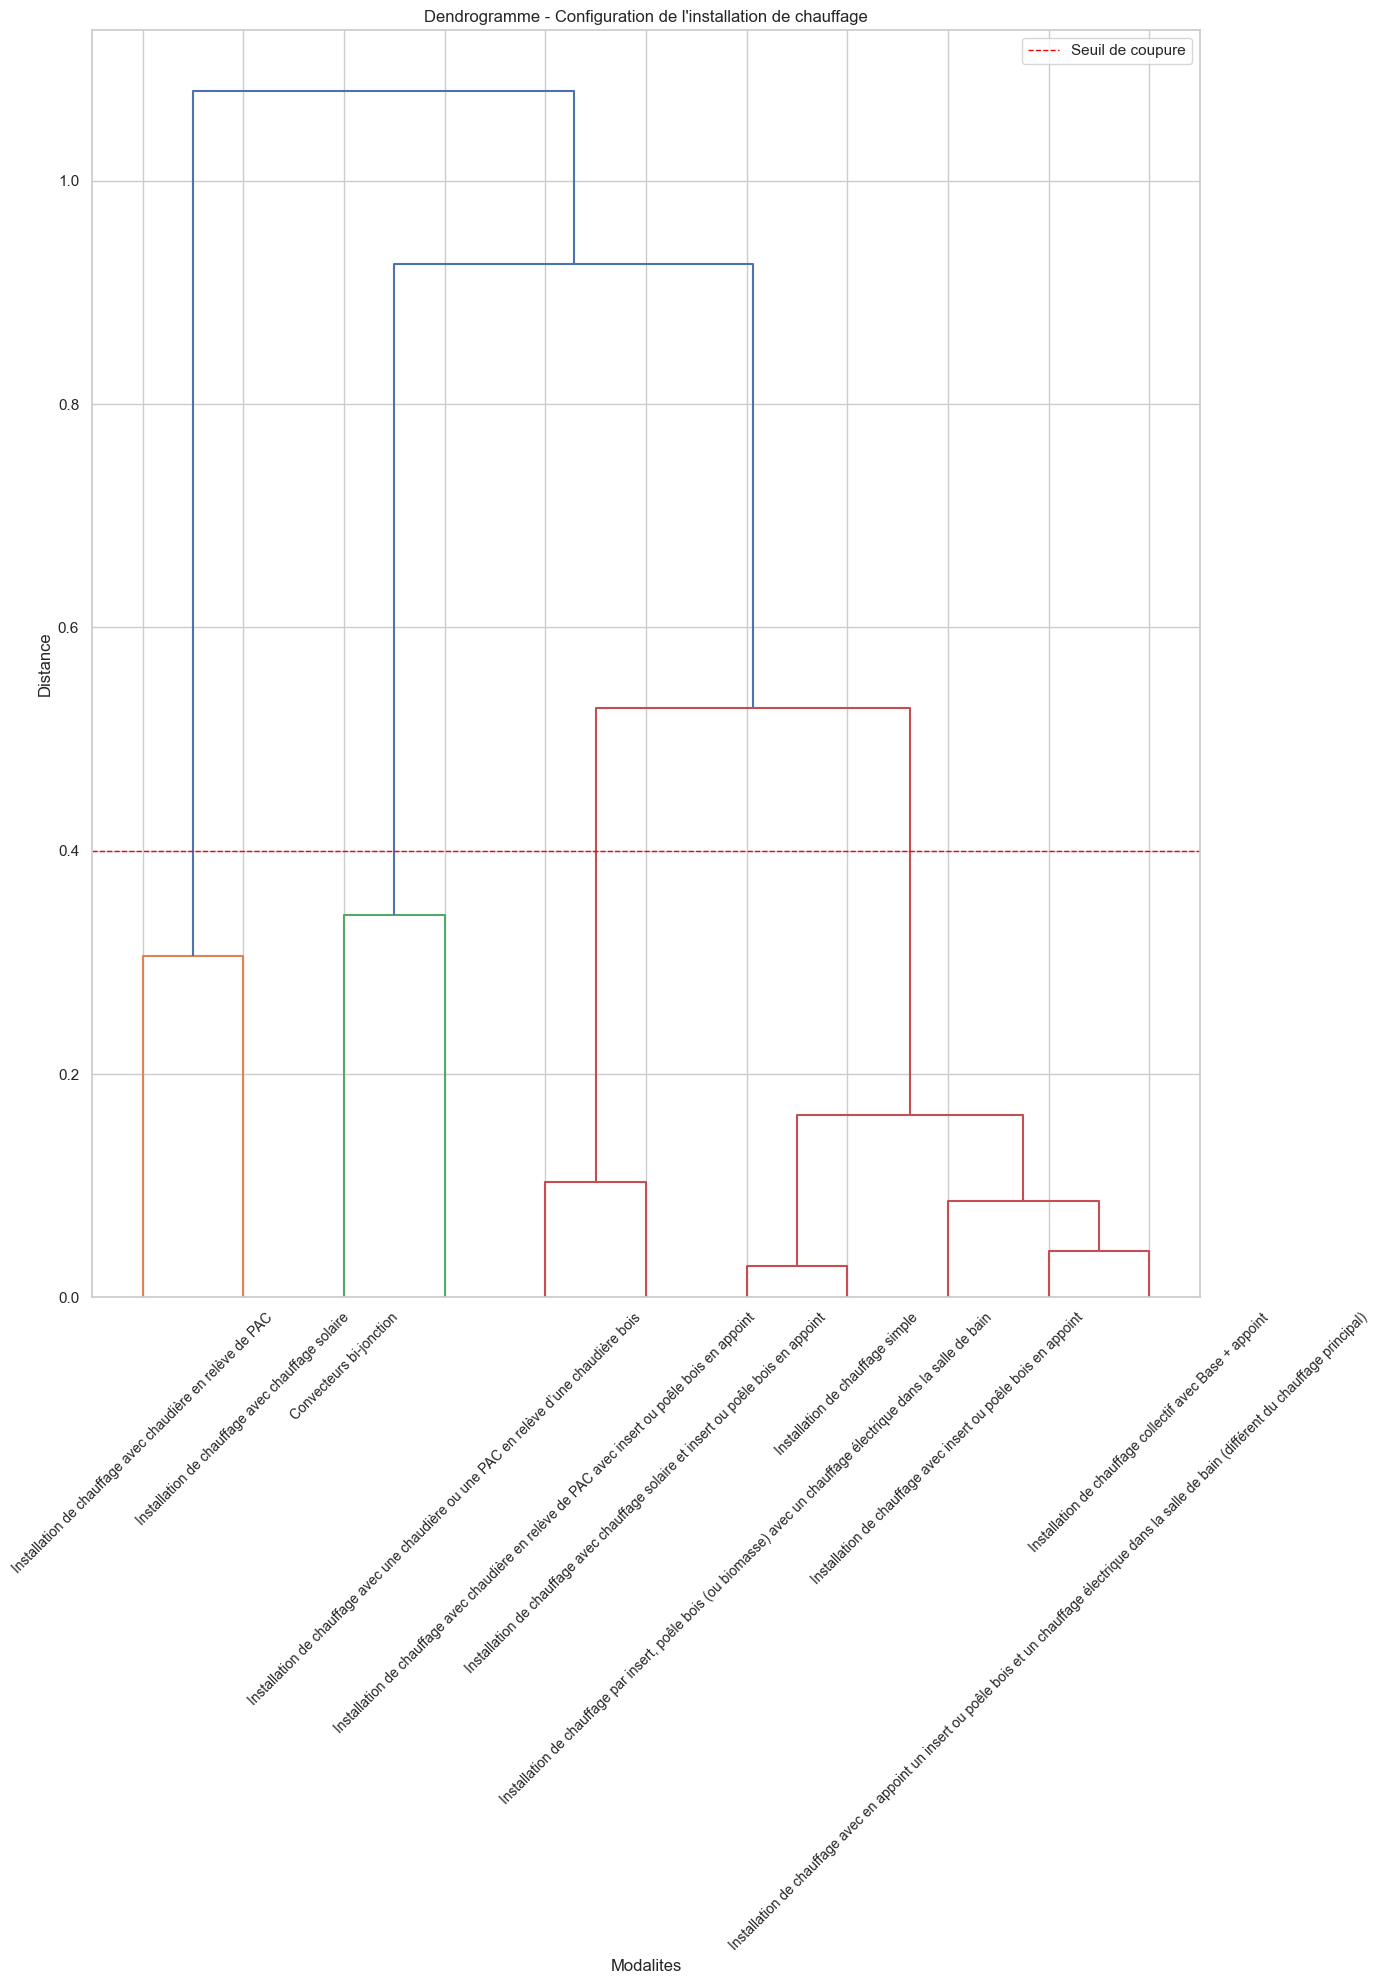

In [47]:
Z_conf_install = linkage(tab_conf_install, method='ward')

plt.figure(figsize=(14, 20))
dendrogram(Z_conf_install, labels=tab_conf_install.index.tolist(), leaf_rotation=45, leaf_font_size=10)
plt.axhline(y=0.4, color='red', linestyle='--', linewidth=1, label='Seuil de coupure')
plt.title("Dendrogramme - Configuration de l'installation de chauffage")
plt.xlabel("Modalites")
plt.ylabel("Distance")
plt.legend()
plt.tight_layout()
plt.show()

In [48]:
df_data_clean['configuration_installation_chauffage_n1'].value_counts(normalize=True)

configuration_installation_chauffage_n1
Installation de chauffage simple                                                                                                                         0.917716
Installation de chauffage avec insert ou poêle bois en appoint                                                                                           0.073631
Installation de chauffage avec en appoint un insert ou poêle bois et un chauffage électrique dans la salle de bain (différent du chauffage principal)    0.003035
Installation de chauffage avec chaudière en relève de PAC                                                                                                0.001987
Installation de chauffage par insert, poêle bois (ou biomasse) avec un chauffage électrique dans la salle de bain                                        0.001554
Installation de chauffage collectif avec Base + appoint                                                                                               

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Le clustering met en evidence des groupes selon le niveau de performance du systeme de
chauffage. On definit un mapping en categories `standard`, `intermediaire`, `performant`
selon la position de chaque modalite dans le dendrogramme et sa repartition DPE associee.

### 7.3 Type d'energie principale de chauffage

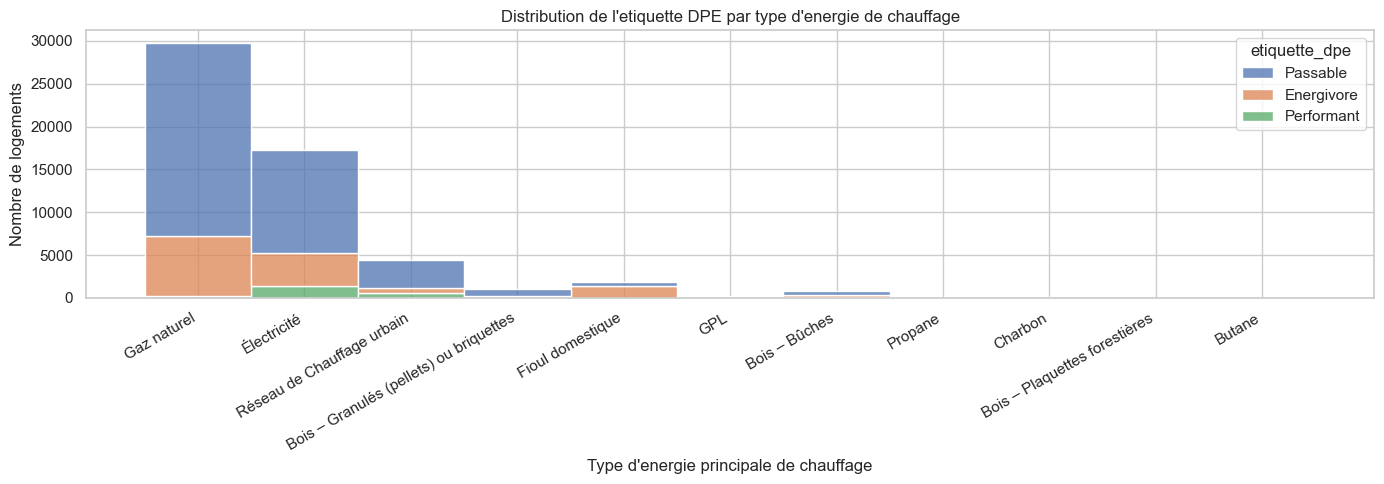

In [49]:
plt.figure(figsize=(14, 5))
sns.histplot(data=df_data_clean, x="type_energie_principale_chauffage", hue="etiquette_dpe", multiple="stack")
plt.title("Distribution de l'etiquette DPE par type d'energie de chauffage")
plt.xlabel("Type d'energie principale de chauffage")
plt.ylabel("Nombre de logements")
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [50]:
tab_en_prin_chauf = pd.crosstab(
    df_data_clean["type_energie_principale_chauffage"],
    df_data_clean["etiquette_dpe"],
    normalize="index"
)
tab_en_prin_chauf.round(3)

etiquette_dpe,Energivore,Passable,Performant
type_energie_principale_chauffage,,,
Bois – Bûches,0.352,0.569,0.080
Bois – Granulés (pellets) ou briquettes,0.184,0.717,0.099
Bois – Plaquettes forestières,0.667,0.333,0.000
Butane,1.000,0.000,0.000
Charbon,0.981,0.019,0.000
Fioul domestique,0.785,0.214,0.001
GPL,0.426,0.568,0.006
Gaz naturel,0.234,0.757,0.008
Propane,0.469,0.490,0.041


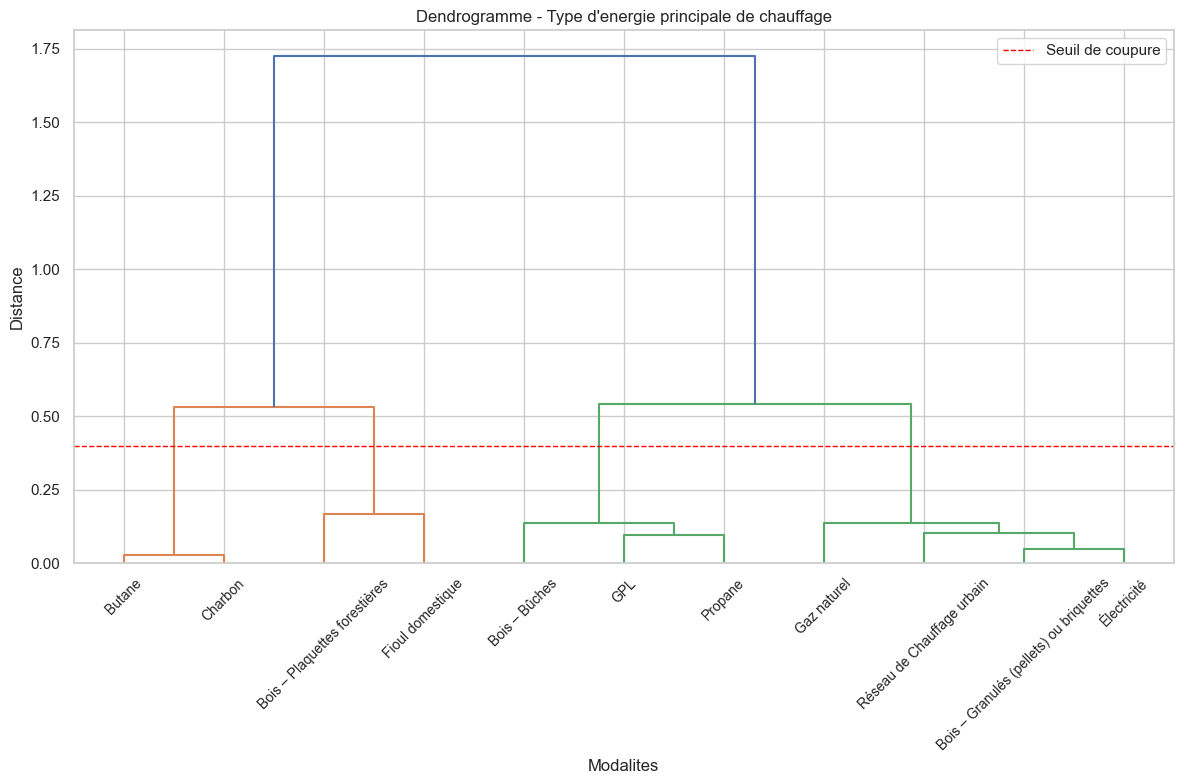

In [51]:
Z_en_prin_chauf = linkage(tab_en_prin_chauf, method='ward')

plt.figure(figsize=(12, 8))
dendrogram(Z_en_prin_chauf, labels=tab_en_prin_chauf.index.tolist(), leaf_rotation=45, leaf_font_size=10)
plt.axhline(y=0.4, color='red', linestyle='--', linewidth=1, label='Seuil de coupure')
plt.title("Dendrogramme - Type d'energie principale de chauffage")
plt.xlabel("Modalites")
plt.ylabel("Distance")
plt.legend()
plt.tight_layout()
plt.show()

#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Les energies se regroupent naturellement par famille (bois, gaz liquefies) selon leur profil
DPE. Le bois performant (granules) se distingue du bois traditionnel (buches, plaquettes), et
les gaz liquefies (GPL, propane, butane) sont fusionnes en une seule categorie. Les autres
energies (gaz naturel, electricite, fioul, reseau urbain, charbon) sont conservees telles
quelles.

### 7.4 Construction des mappings d'agregation

In [52]:
mapping_periode_construction = {
    'avant 1948': 'ancien',
    '1948-1974': 'ancien',

    '1975-1977': 'transition',
    '1978-1982': 'transition',
    '1983-1988': 'transition',

    '1989-2000': 'moderne',
    '2001-2005': 'moderne',
    '2006-2012': 'moderne',

    '2013-2021': 'recent',
    'après 2021': 'tres_recent',
}

mapping_configuration_installation_chauffage_n1 = {
    'Installation de chauffage simple': 'standard',
    'Installation de chauffage avec insert ou poêle bois en appoint': 'intermediaire',
    'Installation de chauffage avec en appoint un insert ou poêle bois et un chauffage électrique dans la salle de bain (différent du chauffage principal)': 'intermediaire',
    'Installation de chauffage avec chaudière en relève de PAC': 'performant',
    'Installation de chauffage par insert, poêle bois (ou biomasse) avec un chauffage électrique dans la salle de bain': 'intermediaire',
    'Installation de chauffage collectif avec Base + appoint': 'standard',
    'Installation de chauffage avec chauffage solaire': 'intermediaire',
    'Installation de chauffage avec chaudière en relève de PAC avec insert ou poêle bois en appoint': 'performant',
    'Installation de chauffage avec une chaudière ou une PAC en relève d’une chaudière bois': 'performant',
    'Installation de chauffage avec chauffage solaire et insert ou poêle bois en appoint': 'intermediaire',
    'Convecteurs bi-jonction': 'standard',
}

mapping_type_energie_principale_chauffage = {
    # Bois
    'Bois – Granulés (pellets) ou briquettes': 'Bois performant',
    'Bois – Bûches': 'Bois traditionnel',
    'Bois – Plaquettes forestières': 'Bois traditionnel',

    # Gaz liquéfiés
    'GPL': 'Gaz liquéfié',
    'Propane': 'Gaz liquéfié',
    'Butane': 'Gaz liquéfié',

    # Conservés tels quels
    'Gaz naturel': 'Gaz naturel',
    'Électricité': 'Électricité',
    'Fioul domestique': 'Fioul domestique',
    'Réseau de Chauffage urbain': 'Réseau de Chauffage urbain',
    'Charbon': 'Charbon',
}

list_mapping = [
    ('periode_construction', mapping_periode_construction),
    ('configuration_installation_chauffage_n1', mapping_configuration_installation_chauffage_n1),
    ('type_energie_principale_chauffage', mapping_type_energie_principale_chauffage),
]

print("Mappings construits :")
for col, mapping_dict in list_mapping:
    print(f"  {col} -> {len(set(mapping_dict.values()))} categories")

Mappings construits :
  periode_construction -> 5 categories
  configuration_installation_chauffage_n1 -> 3 categories
  type_energie_principale_chauffage -> 8 categories


## 8. Regroupement des modalites rares (haute cardinalite)

Trois variables possedent un tres grand nombre de modalites :

- `type_generateur_n1_installation_n1` (environ 130 modalites)
- `type_generateur_n1_ecs_n1` (environ 95 modalites)
- `type_emetteur_installation_chauffage_n1` (environ 46 modalites)

Un encodage One-Hot brut produirait plus de 270 colonnes creuses, dont la majorite aurait
moins de 50 occurrences, ce qui degraderait la generalisation du modele. On regroupe sous
le label `Autre` toute modalite representant moins de 1% de l'effectif.

In [53]:
high_card_cols = [c for c in [
    "type_generateur_n1_installation_n1",
    "type_generateur_n1_ecs_n1",
    "type_emetteur_installation_chauffage_n1",
] if c in df_data_clean.columns]

print(f"{'Variable':<45} {'Avant':>8} {'Apres':>8}  {'Modalites rares regroupees'}")
print("-" * 95)

for col in high_card_cols:
    total = len(df_data_clean)
    counts = df_data_clean[col].value_counts()
    threshold_n = total * 1.0 / 100
    rare = counts[counts < threshold_n].index.tolist()

    n_before = df_data_clean[col].nunique()
    df_data_clean[col] = df_data_clean[col].apply(lambda x: 'Autre' if x in rare else x)
    n_after = df_data_clean[col].nunique()

    print(f"{col:<45} {n_before:>8} {n_after:>8}  ({len(rare)} modalites < 1% -> 'Autre')")

Variable                                         Avant    Apres  Modalites rares regroupees
-----------------------------------------------------------------------------------------------
type_generateur_n1_installation_n1                 130       16  (115 modalites < 1% -> 'Autre')
type_generateur_n1_ecs_n1                           95       15  (81 modalites < 1% -> 'Autre')
type_emetteur_installation_chauffage_n1             46       17  (30 modalites < 1% -> 'Autre')


#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Le regroupement des modalites rares reduit fortement la dimensionnalite apres encodage,
ameliore la generalisation du modele et evite les problemes de modalites jamais vues lors de
la prediction sur de nouvelles donnees.

## 9. Encodage ordinal et export final

### 9.1 Application des suppressions et des mappings

In [54]:
df_data_clean_suppr = df_data_clean.drop(columns=suppr_redondance)

for col, mapping_dict in list_mapping:
    df_data_clean_suppr[col] = df_data_clean_suppr[col].map(mapping_dict)

df_data_clean_mapp = df_data_clean_suppr.copy()
df_data_clean_mapp.head()

,etiquette_dpe,type_batiment,periode_construction,hauteur_sous_plafond,classe_inertie_batiment,qualite_isolation_enveloppe,qualite_isolation_murs,qualite_isolation_menuiseries,qualite_isolation_plancher_bas,type_installation_chauffage_n1,configuration_installation_chauffage_n1,type_generateur_n1_installation_n1,type_energie_principale_chauffage,type_emetteur_installation_chauffage_n1,usage_generateur_n1_installation_n1,type_installation_ecs_n1,type_generateur_n1_ecs_n1,type_energie_principale_ecs,volume_stockage_generateur_n1_ecs_n1,ventilation_posterieure_2012
0,Passable,maison,ancien,2.5,Lourde,très bonne,très bonne,bonne,très bonne,installation individuelle,standard,Chaudière gaz à condensation après 2015,Gaz naturel,Autre,chauffage + ecs,installation individuelle,Chaudière gaz à condensation après 2015,Gaz naturel,0.00000,1
1,Energivore,maison,ancien,2.6,Lourde,insuffisante,insuffisante,moyenne,insuffisante,installation individuelle,standard,Chaudière gaz à condensation 2001-2015,Gaz naturel,Radiateur bitube avec robinet thermostatique s...,chauffage + ecs,installation individuelle,Chaudière gaz à condensation 2001-2015,Gaz naturel,0.00000,0
2,Passable,appartement,transition,2.5,Moyenne,très bonne,insuffisante,très bonne,insuffisante,installation individuelle,standard,"Panneau rayonnant électrique NFC, NF** et NF***",Électricité,"Panneau rayonnant NFC, NF** et NF***",chauffage,installation individuelle,CET sur air ambiant (sur local non chauffé) ap...,Électricité,5.01728,1
3,Energivore,maison,ancien,2.5,Légère,moyenne,moyenne,moyenne,insuffisante,installation individuelle,standard,"radiateur électrique NFC, NF** et NF***",Électricité,"radiateur électrique NFC, NF** et NF***",chauffage,installation individuelle,Ballon électrique à accumulation vertical Caté...,Électricité,5.01728,0
4,Passable,maison,moderne,2.5,Moyenne,moyenne,moyenne,moyenne,bonne,installation individuelle,standard,Chaudière gaz à condensation après 2015,Gaz naturel,Radiateur monotube avec robinet thermostatique...,chauffage + ecs,installation individuelle,Chaudière gaz à condensation après 2015,Gaz naturel,0.00000,0


In [55]:
df_data_clean_mapp['qualite_isolation_enveloppe'].unique()

<ArrowStringArray>
['très bonne', 'insuffisante', 'moyenne', 'bonne']
Length: 4, dtype: str

### 9.2 Encodage ordinal

Les variables d'isolation, d'inertie et de periode de construction ont un ordre naturel
(insuffisante < moyenne < bonne < tres bonne). Un encodage ordinal preserve cette relation
d'ordre, contrairement a un One-Hot qui la perdrait.

In [56]:
ordinal_vars = {
    'qualite_isolation_enveloppe':    ['insuffisante', 'moyenne', 'bonne', 'très bonne'],
    'qualite_isolation_murs':         ['insuffisante', 'moyenne', 'bonne', 'très bonne'],
    'qualite_isolation_menuiseries':  ['insuffisante', 'moyenne', 'bonne', 'très bonne'],
    'qualite_isolation_plancher_bas': ['insuffisante', 'moyenne', 'bonne', 'très bonne'],
    'classe_inertie_batiment':        ['Légère', 'Moyenne', 'Lourde', 'Très lourde'],
    'periode_construction':           ['ancien', 'transition', 'moderne', 'recent', 'tres_recent'],
}

for col, order in ordinal_vars.items():
    if col not in df_data_clean_mapp.columns:
        continue

    vals_in_data = set(df_data_clean_mapp[col].dropna().unique())
    vals_in_order = set(order)
    unexpected = vals_in_data - vals_in_order
    if unexpected:
        print(f"Attention : {col} contient des valeurs non prevues dans l'ordre -> {unexpected}")
        order = order + list(unexpected)

    mapping = {v: i for i, v in enumerate(order)}
    df_data_clean_mapp[col + '_enc'] = df_data_clean_mapp[col].map(mapping)
    n_nan = df_data_clean_mapp[col + '_enc'].isnull().sum()
    print(f"{col} -> encode ({len(order)} niveaux, {n_nan} NaN)")

df_data_final = df_data_clean_mapp.drop(columns=list(ordinal_vars.keys()))
df_data_final.head()

qualite_isolation_enveloppe -> encode (4 niveaux, 0 NaN)
qualite_isolation_murs -> encode (4 niveaux, 0 NaN)
qualite_isolation_menuiseries -> encode (4 niveaux, 0 NaN)
qualite_isolation_plancher_bas -> encode (4 niveaux, 0 NaN)
classe_inertie_batiment -> encode (4 niveaux, 0 NaN)
periode_construction -> encode (5 niveaux, 0 NaN)


,etiquette_dpe,type_batiment,hauteur_sous_plafond,type_installation_chauffage_n1,configuration_installation_chauffage_n1,type_generateur_n1_installation_n1,type_energie_principale_chauffage,type_emetteur_installation_chauffage_n1,usage_generateur_n1_installation_n1,type_installation_ecs_n1,type_generateur_n1_ecs_n1,type_energie_principale_ecs,volume_stockage_generateur_n1_ecs_n1,ventilation_posterieure_2012,qualite_isolation_enveloppe_enc,qualite_isolation_murs_enc,qualite_isolation_menuiseries_enc,qualite_isolation_plancher_bas_enc,classe_inertie_batiment_enc,periode_construction_enc
0,Passable,maison,2.5,installation individuelle,standard,Chaudière gaz à condensation après 2015,Gaz naturel,Autre,chauffage + ecs,installation individuelle,Chaudière gaz à condensation après 2015,Gaz naturel,0.00000,1,3,3,2,3,2,0
1,Energivore,maison,2.6,installation individuelle,standard,Chaudière gaz à condensation 2001-2015,Gaz naturel,Radiateur bitube avec robinet thermostatique s...,chauffage + ecs,installation individuelle,Chaudière gaz à condensation 2001-2015,Gaz naturel,0.00000,0,0,0,1,0,2,0
2,Passable,appartement,2.5,installation individuelle,standard,"Panneau rayonnant électrique NFC, NF** et NF***",Électricité,"Panneau rayonnant NFC, NF** et NF***",chauffage,installation individuelle,CET sur air ambiant (sur local non chauffé) ap...,Électricité,5.01728,1,3,0,3,0,1,1
3,Energivore,maison,2.5,installation individuelle,standard,"radiateur électrique NFC, NF** et NF***",Électricité,"radiateur électrique NFC, NF** et NF***",chauffage,installation individuelle,Ballon électrique à accumulation vertical Caté...,Électricité,5.01728,0,1,1,1,0,0,0
4,Passable,maison,2.5,installation individuelle,standard,Chaudière gaz à condensation après 2015,Gaz naturel,Radiateur monotube avec robinet thermostatique...,chauffage + ecs,installation individuelle,Chaudière gaz à condensation après 2015,Gaz naturel,0.00000,0,1,1,1,2,1,2


#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation :</span>

Chaque variable a ordre naturel est remplacee par sa version encodee (`_enc`), preservant la
relation d'ordre entre les modalites. C'est un avantage notable pour les modeles lineaires
(regression logistique), qui peuvent exploiter directement cette relation monotone.

### 9.3 Export

In [ ]:
df_data_final.to_excel('../data/data_for_processing_final1.xlsx', index=False)
print(f"Export termine : {df_data_final.shape[0]:,} lignes x {df_data_final.shape[1]} colonnes")

Export termine : 55,357 lignes x 20 colonnes


#### <span style="text-decoration: underline; color:red; font-weight:bold;">Interpretation finale :</span>

Le jeu de donnees est desormais nettoye (variables non pertinentes, quasi-constantes et
fortement manquantes supprimees), debarrasse des redondances, les outliers ont ete corriges,
et les variables categorielles a forte cardinalite ont ete regroupees de facon coherente avec
le pouvoir discriminant sur l'etiquette DPE. Le jeu de donnees est pret pour l'encodage final
(TargetEncoder / OneHot) et la modelisation.